<a href="https://colab.research.google.com/github/ViniFigueiredo/teste-notebook/blob/main/predicao_votos_senado_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição de Votos Nominais no Senado Federal (2010–2022)
## Pipeline Base Modular — Replicação Metodológica (VPF - Mizrahi et al., 2025 & Albuquerque et al., 2025)

---
## Célula 1: Importação de Bibliotecas e Configuração de Ambiente
### 1.1 Dependências, Sementes Globais de Reprodutibilidade e Conexão ao Data Warehouse
Importação padronizada das bibliotecas de manipulação de dados (`pandas`, `numpy`), visualização científica (`matplotlib`, `seaborn`), conexão SQL (`sqlite3`), vetorização semântica (`sentence-transformers`), redução dimensional (`PCA`, `TruncatedSVD`), pré-processamento (`OneHotEncoder`, `StandardScaler`, `LabelEncoder`), validação e busca de hiperparâmetros (`RandomizedSearchCV`, `PredefinedSplit`) e os 7 algoritmos supervisionados.

In [ ]:
# =============================================================================
# CÉLULA 1.1: IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÃO DE AMBIENTE
# =============================================================================
!pip install -q sentence-transformers xgboost lightgbm

import os
import time
import sqlite3
import warnings
warnings.filterwarnings("ignore")

# Manipulação de dados, álgebra linear e visualização
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["font.size"] = 11

# Vetorização semântica (PLN / Sentence-BERT)
from sentence_transformers import SentenceTransformer

# Redução de dimensionalidade, pré-processamento e validação temporal
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from scipy.stats import randint, uniform, loguniform

# Métricas de avaliação supervisionada
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    matthews_corrcoef
)

# Painel de Algoritmos Supervisionados (Quinteto VPF + LightGBM & Naive Bayes)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Hiperparâmetros estruturais e sementes globais de reprodutibilidade (ERRO-14)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
RNG = np.random.default_rng(RANDOM_STATE)

PCA_N_COMPONENTS = 50
SVD_N_COMPONENTS = 2
EMBED_MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"

# Resolução automática do caminho do Data Warehouse SQLite (Local ou Google Colab)
DB_CANDIDATES = [
    "senado_votos_dw.db",
    "/content/senado_votos_dw.db",
    "/content/drive/MyDrive/senado_votos_dw.db",
    "/run/media/anon/2d9cd7a1-c5cb-4ba9-9ab8-d7112d0743ac1/tcc/Processamento em Linguagem Natural/politico/senado_votos_dw.db",
    "Processamento em Linguagem Natural/politico/senado_votos_dw.db"
]
DB_PATH = next((p for p in DB_CANDIDATES if os.path.exists(p)), "senado_votos_dw.db")

print(f"✓ Ambiente configurado com sucesso. Data Warehouse: {DB_PATH} (encontrado={os.path.exists(DB_PATH)})")

✓ Ambiente configurado com sucesso. Data Warehouse: senado_votos_dw.db (encontrado=True)


---
## Célula 2: Extração de Dados (Data Warehouse) e Análise Exploratória (EDA)
### 2.1 Carga SQL Unificada (`fato_voto_parlamentar`) e Codificação da Variável Alvo
Extração das votações nominais ostensivas no período **2010–2022** (53ª à 56ª Legislatura), articulando as dimensões de tempo, senador, partido, coalizão governamental, matéria legislativa (`ementa`, `tipo_materia`, `categoria_tematica`), sessão de votação e autoria de emendas.

In [ ]:
# =============================================================================
# CÉLULA 2.1: EXTRAÇÃO E CARGA INICIAL DE DADOS (DATA WAREHOUSE)
# =============================================================================
DB_PATH = next((p for p in DB_CANDIDATES if os.path.exists(p)), DB_PATH)
assert os.path.exists(DB_PATH), (
    f"Banco de dados não encontrado em: {DB_PATH}. "
    "Se estiver usando o kernel remoto do Google Colab no VS Code, clique com o "
    "botão direito em 'senado_votos_dw.db' no Explorer do VS Code e selecione 'Upload to Colab'."
)

QUERY_DW = """
SELECT
    -- Chaves identificadoras
    f.id_fato_voto,
    f.sk_senador,
    f.sk_materia,
    f.sk_votacao,
    f.sk_partido,

    -- Variável Alvo (Target Nominal)
    tv.categoria_voto,

    -- Dimensão Temporal
    t.data_completa,
    t.ano,
    t.mes,
    t.trimestre,
    t.numero_legislatura,
    t.ano_legislatura,

    -- Dimensão Parlamentar
    s.nome_parlamentar,
    s.sexo,
    s.sigla_uf       AS uf,
    s.regiao_uf      AS regiao,

    -- Dimensão Partidária e Coalizão Governamental
    p.sigla_partido,
    COALESCE(sp.situacao, 'DESCONHECIDO') AS situacao_coalizao,
    COALESCE(sp.flag_base_aliada, 0)      AS flag_base_aliada,
    COALESCE(sp.presidente, 'DESCONHECIDO') AS governo,

    -- Dimensão da Matéria Legislativa
    COALESCE(m.categoria_tematica, 'OUTROS') AS categoria_tematica,
    COALESCE(m.eh_projeto_lei, 0)            AS eh_projeto_lei,
    COALESCE(m.eh_orcamento, 0)              AS eh_orcamento,
    COALESCE(m.sigla_tipo, 'OUTROS')         AS tipo_materia,
    m.ementa,                                -- texto normativo da matéria (embeddings SBERT)

    -- Dimensão da Sessão de Votação e Texto Normativo
    v.descricao_votacao,
    v.resultado_votacao,
    v.texto_completo_votacao,

    -- Engajamento Legislativo (Autoria de Emendas na Matéria)
    COALESCE(e.n_emendas_autor, 0) AS n_emendas_autor

FROM fato_voto_parlamentar f
JOIN dim_tempo t      ON f.sk_tempo = t.sk_tempo
JOIN dim_senador s    ON f.sk_senador = s.sk_senador
JOIN dim_partido p    ON f.sk_partido = p.sk_partido
JOIN dim_tipo_voto tv ON f.sk_tipo_voto = tv.sk_tipo_voto
JOIN dim_materia m    ON f.sk_materia = m.sk_materia
JOIN dim_votacao v    ON f.sk_votacao = v.sk_votacao
LEFT JOIN dim_situacao_partido_periodo sp
    ON f.sk_partido = sp.sk_partido
    AND t.data_completa BETWEEN sp.data_inicio
                        AND COALESCE(sp.data_fim, '9999-12-31')
LEFT JOIN (
    SELECT sk_senador_autor AS sk_senador, sk_materia, COUNT(*) AS n_emendas_autor
    FROM dim_emenda_legislativa
    WHERE sk_senador_autor IS NOT NULL
    GROUP BY sk_senador_autor, sk_materia
) e ON f.sk_senador = e.sk_senador AND f.sk_materia = e.sk_materia

WHERE t.ano BETWEEN 2010 AND 2022
  AND f.votacao_secreta_flag = 0
  AND v.votacao_secreta = 'N'
  AND tv.categoria_voto NOT IN ('PRESIDENCIA', 'OUTROS', 'SECRETO', 'OBSTRUCAO')
  AND p.sigla_partido != 'OUTROS'
"""

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql(QUERY_DW, conn)

# Garantia de retenção exclusiva das 4 classes nominais válidas
CLASSES_VALIDAS = ["FAVORAVEL", "CONTRARIO", "ABSTENCAO", "AUSENCIA"]
df = df[df["categoria_voto"].isin(CLASSES_VALIDAS)].copy().reset_index(drop=True)

# Codificação numérica do Target (0..3) — ajustado uma única vez globalmente
le_target = LabelEncoder()
df["target"] = le_target.fit_transform(df["categoria_voto"])

print(f"✓ Carga concluída: {len(df):,} votos nominais válidos (2010–2022)")
print(f"  • Sessões de votação distintas : {df['sk_votacao'].nunique():,}")
print(f"  • Matérias distintas           : {df['sk_materia'].nunique():,}")
print(f"  • Senadores distintos          : {df['sk_senador'].nunique():,}")
print("\nDistribuição das classes do Target:")
for idx, cls in enumerate(le_target.classes_):
    n_cls = (df["target"] == idx).sum()
    print(f"  [{idx}] {cls:10s}: {n_cls:7,d} votos ({n_cls / len(df):.2%})")

✓ Carga concluída: 60,104 votos nominais válidos (2010–2022)
  • Sessões de votação distintas : 763
  • Matérias distintas           : 489
  • Senadores distintos          : 324

Distribuição das classes do Target:
  [0] ABSTENCAO :   6,142 votos (10.22%)
  [1] AUSENCIA  :   5,293 votos (8.81%)
  [2] CONTRARIO :   9,569 votos (15.92%)
  [3] FAVORAVEL :  39,100 votos (65.05%)


### 2.2 Análise Exploratória (EDA) — Distribuição Global e Desbalanceamento do Target
Inspeção visual do desbalanceamento estrutural entre votos positivos (`FAVORAVEL`), negativos (`CONTRARIO`), abstenções (`ABSTENCAO`) e ausências (`AUSENCIA`) no plenário do Senado Federal.

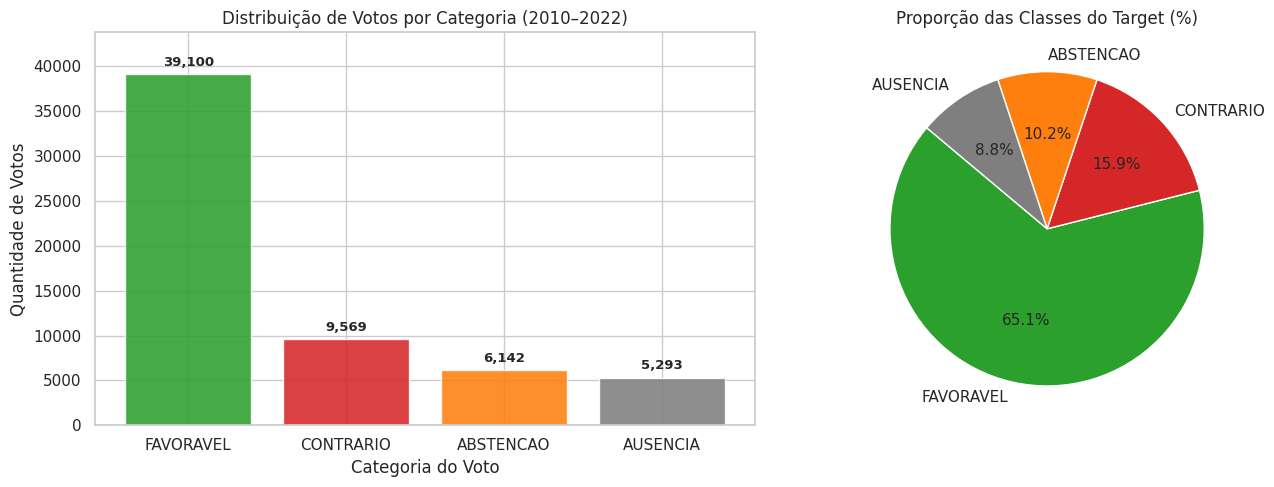

In [ ]:
# =============================================================================
# CÉLULA 2.2: EDA — DISTRIBUIÇÃO GLOBAL E DESBALANCEAMENTO DO TARGET
# =============================================================================
ORDEM_VOTOS = ["FAVORAVEL", "CONTRARIO", "ABSTENCAO", "AUSENCIA"]
CORES_VOTOS = {
    "FAVORAVEL": "#2ca02c",  # verde (voto positivo)
    "CONTRARIO": "#d62728",  # vermelho (voto negativo)
    "ABSTENCAO": "#ff7f0e",  # laranja (abstenção)
    "AUSENCIA":  "#7f7f7f",  # cinza (ausência)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vc = df["categoria_voto"].value_counts().reindex(ORDEM_VOTOS)
axes[0].bar(
    vc.index, vc.values,
    color=[CORES_VOTOS[c] for c in vc.index], alpha=0.88
)
axes[0].set_title("Distribuição de Votos por Categoria (2010–2022)")
axes[0].set_xlabel("Categoria do Voto")
axes[0].set_ylabel("Quantidade de Votos")
for idx_b, val in enumerate(vc.values):
    axes[0].text(idx_b, val + 600, f"{val:,}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axes[0].set_ylim(0, max(vc.values) * 1.12)

vc_pct = (vc / len(df)) * 100.0
axes[1].pie(
    vc_pct.values,
    labels=vc_pct.index,
    autopct="%1.1f%%",
    colors=[CORES_VOTOS[c] for c in vc_pct.index],
    startangle=140
)
axes[1].set_title("Proporção das Classes do Target (%)")

plt.tight_layout()
plt.show()

### 2.3 Análise Exploratória (EDA) — Cobertura da Coalizão Governamental e Alinhamento por Mandato
Análise da composição da base governista, oposição e blocos independentes por governo presidencial e da proporção de votos positivos/negativos/abstenções segundo o posicionamento na coalizão.

✓ Cobertura de coalizão governamental no período 2010–2022: 98.91%


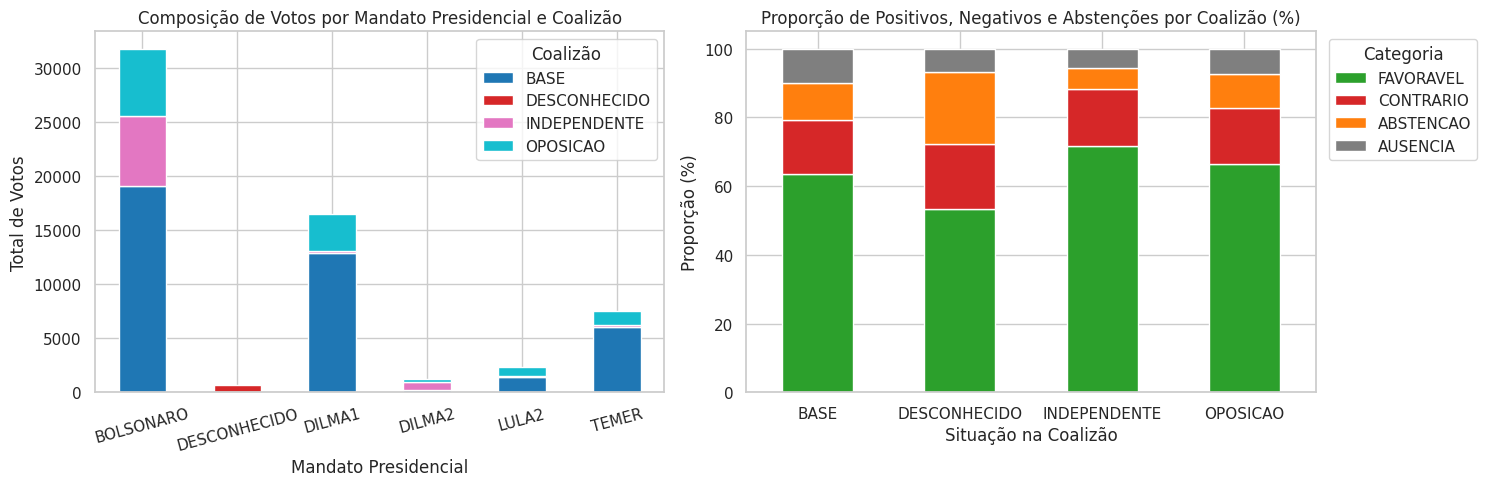


Tabela Percentual — Situação na Coalizão × Categoria de Voto (%):
categoria_voto     FAVORAVEL  CONTRARIO  ABSTENCAO  AUSENCIA
situacao_coalizao                                           
BASE                   63.52      15.66      10.90      9.92
DESCONHECIDO           53.34      19.00      20.97      6.69
INDEPENDENTE           71.77      16.48       6.22      5.52
OPOSICAO               66.49      16.26       9.91      7.34


In [ ]:
# =============================================================================
# CÉLULA 2.3: EDA — COBERTURA DA COALIZÃO GOVERNAMENTAL E VOTO POR BLOCO
# =============================================================================
cobertura_pct = (df["situacao_coalizao"] != "DESCONHECIDO").mean() * 100.0
print(f"✓ Cobertura de coalizão governamental no período 2010–2022: {cobertura_pct:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_gov = df.groupby(["governo", "situacao_coalizao"]).size().unstack(fill_value=0)
df_gov.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Composição de Votos por Mandato Presidencial e Coalizão")
axes[0].set_xlabel("Mandato Presidencial")
axes[0].set_ylabel("Total de Votos")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Coalizão", loc="upper right")

coal_voto = (
    pd.crosstab(df["situacao_coalizao"], df["categoria_voto"], normalize="index")
    .reindex(columns=ORDEM_VOTOS, fill_value=0.0) * 100.0
)
coal_voto.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=[CORES_VOTOS[c] for c in ORDEM_VOTOS]
)
axes[1].set_title("Proporção de Positivos, Negativos e Abstenções por Coalizão (%)")
axes[1].set_xlabel("Situação na Coalizão")
axes[1].set_ylabel("Proporção (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Categoria", bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()

print("\nTabela Percentual — Situação na Coalizão × Categoria de Voto (%):")
print(coal_voto.round(2).to_string())

### 2.4 Análise Exploratória (EDA) — Evolução por Legislatura (53ª–56ª) e Série Histórica Anual (2010–2022)
Distribuição temporal das categorias de voto entre legislaturas e evolução anual do volume de votos e sessões nominais.

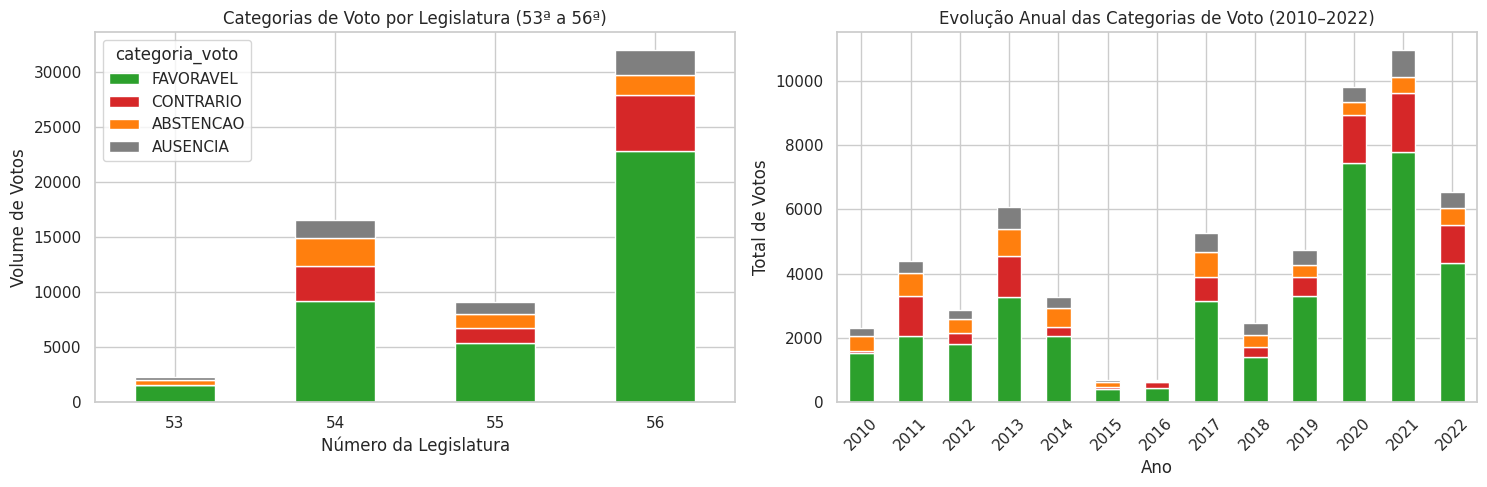

In [ ]:
# =============================================================================
# CÉLULA 2.4: EDA — DISTRIBUIÇÃO POR LEGISLATURA E SÉRIE ANUAL (2010–2022)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

pivot_legis = (
    df.groupby(["numero_legislatura", "categoria_voto"]).size()
    .unstack(fill_value=0).reindex(columns=ORDEM_VOTOS, fill_value=0)
)
pivot_legis.plot(
    kind="bar", stacked=True, ax=axes[0],
    color=[CORES_VOTOS[c] for c in ORDEM_VOTOS]
)
axes[0].set_title("Categorias de Voto por Legislatura (53ª a 56ª)")
axes[0].set_xlabel("Número da Legislatura")
axes[0].set_ylabel("Volume de Votos")
axes[0].tick_params(axis="x", rotation=0)

pivot_ano = (
    df.groupby(["ano", "categoria_voto"]).size()
    .unstack(fill_value=0).reindex(columns=ORDEM_VOTOS, fill_value=0)
)
pivot_ano.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=[CORES_VOTOS[c] for c in ORDEM_VOTOS], legend=False
)
axes[1].set_title("Evolução Anual das Categorias de Voto (2010–2022)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Total de Votos")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 2.5 Análise Exploratória (EDA) — Tipos de Matéria Legislativa e Ativação de Emendas
Composição das votações por espécie normativa (`PEC`, `PLP`, `MPV`, `PL`, etc.) e evolução anual do engajamento parlamentar por autoria de emendas (`n_emendas_autor > 0`).

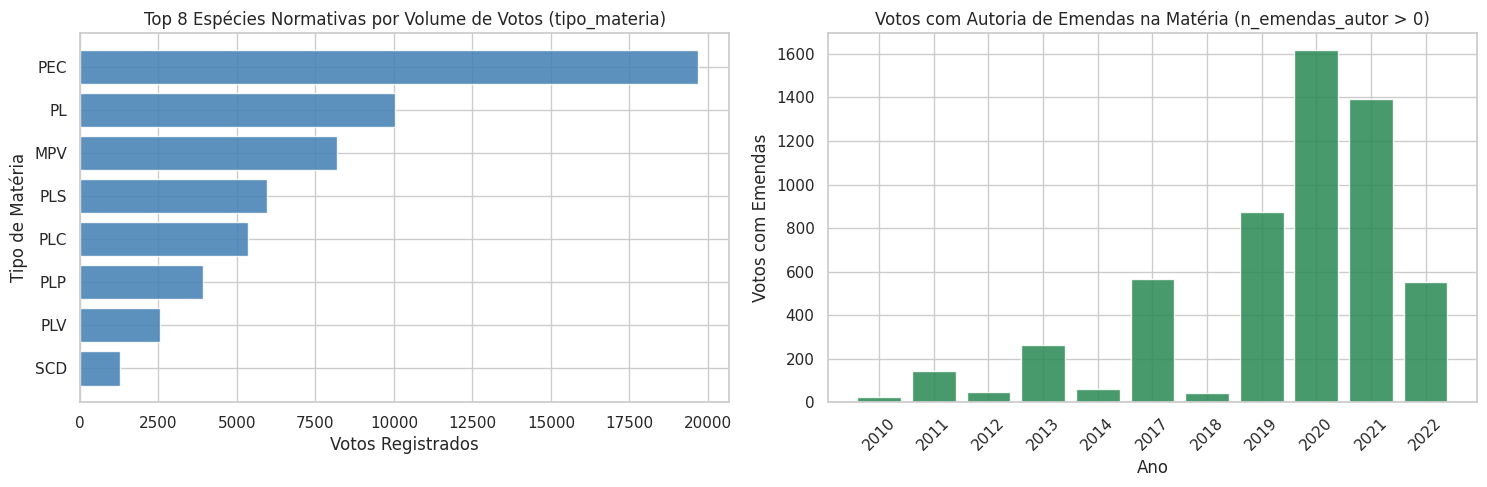

Resumo das 8 Principais Espécies Normativas (Votos, Sessões e % Positivo/Negativo/Abstenção):
              votos  sessoes  materias  pct_favoravel  pct_contrario  pct_abstencao
tipo_materia                                                                       
PEC           19696      251       100          69.10          11.59          10.60
PL            10030      126       104          73.31          15.57           4.35
MPV            8202      103        82          61.19          23.46           7.29
PLS            5971       75        49          61.48          12.11          14.40
PLC            5344       68        50          54.38          20.66          14.52
PLP            3906       49        41          75.40           9.65           6.43
PLV            2551       32        25          45.47          25.40          18.31
SCD            1267       16         6          50.28          22.81          19.65


In [ ]:
# =============================================================================
# CÉLULA 2.5: EDA — TIPOS DE MATÉRIA LEGISLATIVA E ATIVAÇÃO DE EMENDAS
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

top_tipos = df["tipo_materia"].value_counts().head(8)
axes[0].barh(top_tipos.index[::-1], top_tipos.values[::-1], color="steelblue", alpha=0.88)
axes[0].set_title("Top 8 Espécies Normativas por Volume de Votos (tipo_materia)")
axes[0].set_xlabel("Votos Registrados")
axes[0].set_ylabel("Tipo de Matéria")

emendas_por_ano = df[df["n_emendas_autor"] > 0].groupby("ano").size()
axes[1].bar(emendas_por_ano.index.astype(str), emendas_por_ano.values, color="seagreen", alpha=0.88)
axes[1].set_title("Votos com Autoria de Emendas na Matéria (n_emendas_autor > 0)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Votos com Emendas")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

resumo_tipos = (
    df.groupby("tipo_materia")
    .agg(
        votos=("id_fato_voto", "count"),
        sessoes=("sk_votacao", "nunique"),
        materias=("sk_materia", "nunique"),
        pct_favoravel=("categoria_voto", lambda s: (s == "FAVORAVEL").mean() * 100),
        pct_contrario=("categoria_voto", lambda s: (s == "CONTRARIO").mean() * 100),
        pct_abstencao=("categoria_voto", lambda s: (s == "ABSTENCAO").mean() * 100),
    )
    .sort_values("votos", ascending=False)
    .head(8)
    .round(2)
)
print("Resumo das 8 Principais Espécies Normativas (Votos, Sessões e % Positivo/Negativo/Abstenção):")
print(resumo_tipos.to_string())

### 2.6 Análise Exploratória (EDA) — Votos Positivos (`FAVORAVEL`), Negativos (`CONTRARIO`) e Abstenções (`ABSTENCAO` / `AUSENCIA`) por Partido
Decomposição em volume absoluto e em proporção interna (100% empilhada) dos votos positivos, negativos, abstenções e ausências para as 15 maiores bancadas partidárias do Senado Federal.

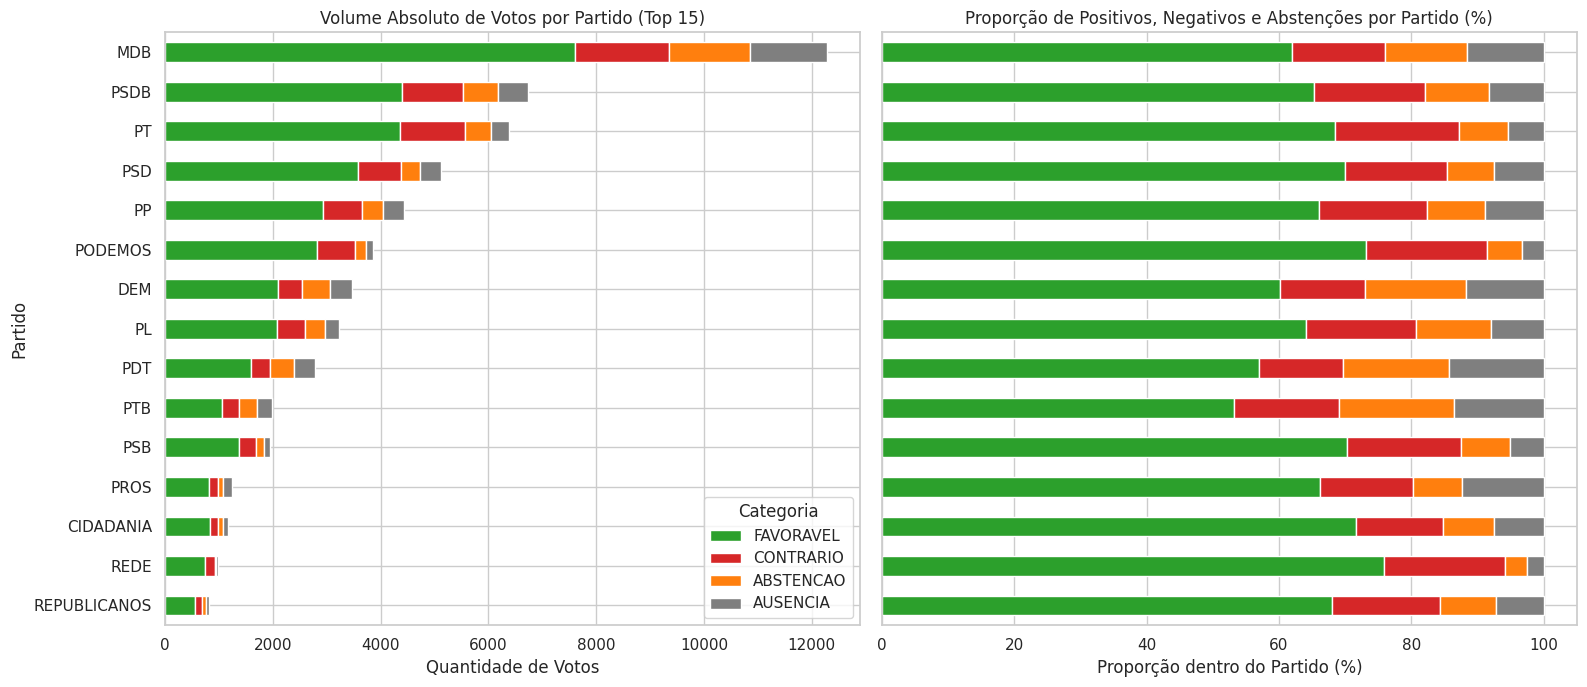

Tabela Completa — Votos Positivos (FAVORAVEL), Negativos (CONTRARIO), Abstenções e Ausências por Partido (Top 15):
categoria_voto  FAVORAVEL  CONTRARIO  ABSTENCAO  AUSENCIA  Total  FAVORAVEL (%)  CONTRARIO (%)  ABSTENCAO (%)  AUSENCIA (%)
sigla_partido                                                                                                              
MDB                  7609       1735       1518      1427  12289          61.92          14.12          12.35         11.61
PSDB                 4402       1121        652       561   6736          65.35          16.64           9.68          8.33
PT                   4368       1199        473       348   6388          68.38          18.77           7.40          5.45
PSD                  3585        790        363       390   5128          69.91          15.41           7.08          7.61
PP                   2930        718        392       393   4433          66.10          16.20           8.84          8.87
PODEMOS          

In [ ]:
# =============================================================================
# CÉLULA 2.6: EDA — VOTOS POSITIVOS, NEGATIVOS E ABSTENÇÕES POR PARTIDO
# =============================================================================
top15_partidos = df["sigla_partido"].value_counts().head(15).index.tolist()
df_top_p = df[df["sigla_partido"].isin(top15_partidos)]

ct_abs = (
    pd.crosstab(df_top_p["sigla_partido"], df_top_p["categoria_voto"])
    .reindex(index=top15_partidos[::-1], columns=ORDEM_VOTOS, fill_value=0)
)
ct_pct = ct_abs.div(ct_abs.sum(axis=1), axis=0) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

ct_abs.plot(
    kind="barh", stacked=True, ax=axes[0],
    color=[CORES_VOTOS[c] for c in ORDEM_VOTOS]
)
axes[0].set_title("Volume Absoluto de Votos por Partido (Top 15)")
axes[0].set_xlabel("Quantidade de Votos")
axes[0].set_ylabel("Partido")
axes[0].legend(title="Categoria", loc="lower right")

ct_pct.plot(
    kind="barh", stacked=True, ax=axes[1],
    color=[CORES_VOTOS[c] for c in ORDEM_VOTOS], legend=False
)
axes[1].set_title("Proporção de Positivos, Negativos e Abstenções por Partido (%)")
axes[1].set_xlabel("Proporção dentro do Partido (%)")

plt.tight_layout()
plt.show()

tabela_partidos = ct_abs.iloc[::-1].copy()
tabela_partidos["Total"] = tabela_partidos.sum(axis=1)
for col in ORDEM_VOTOS:
    tabela_partidos[f"{col} (%)"] = (tabela_partidos[col] / tabela_partidos["Total"] * 100.0).round(2)

print("Tabela Completa — Votos Positivos (FAVORAVEL), Negativos (CONTRARIO), Abstenções e Ausências por Partido (Top 15):")
print(tabela_partidos.to_string())

### 2.7 Análise Exploratória (EDA) — Rankings Partidários: Taxa de Voto Positivo vs. Negativo vs. Abstenção
Comparação direta entre os partidos com maior propensão ao voto positivo (`% FAVORAVEL`), à oposição explícita em plenário (`% CONTRARIO`) e ao posicionamento estratégico via abstenção (`% ABSTENCAO`), considerando legendas com pelo menos 300 votos registrados.

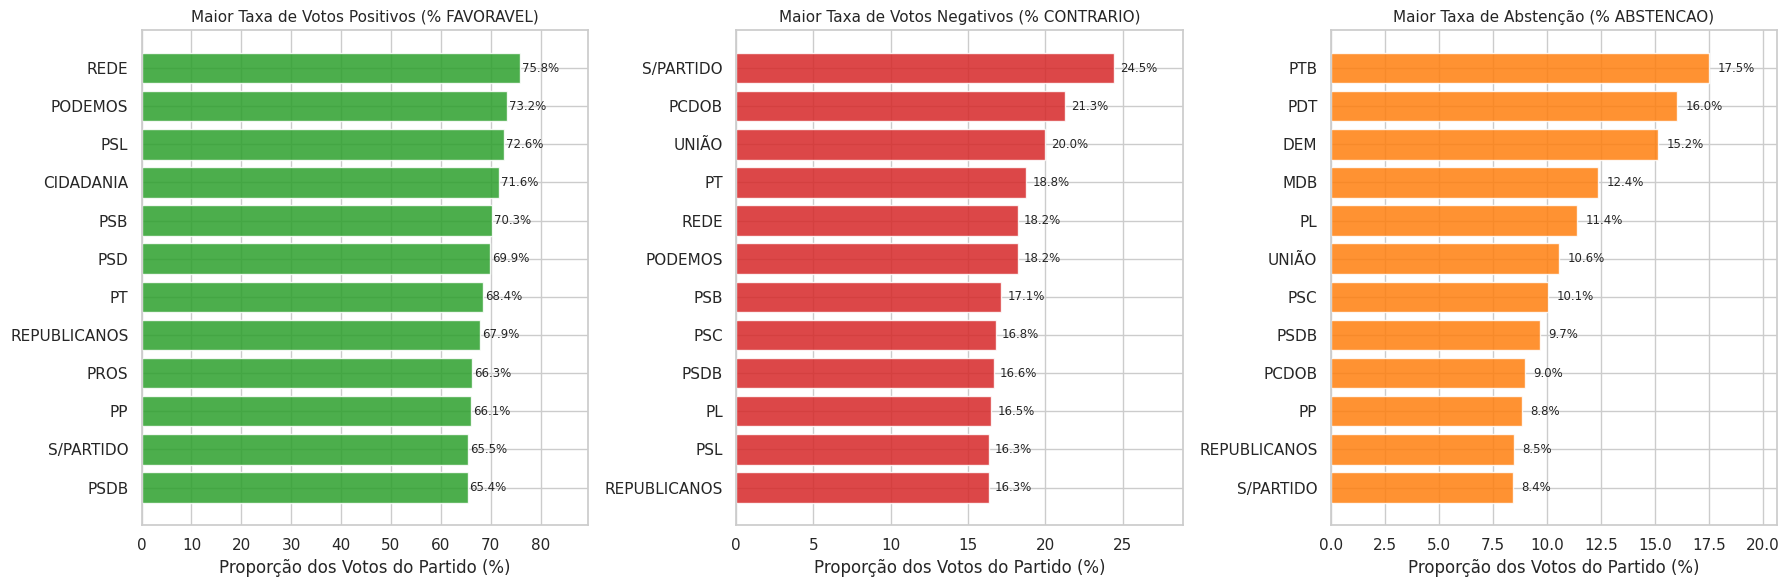

In [ ]:
# =============================================================================
# CÉLULA 2.7: EDA — RANKINGS PARTIDÁRIOS (% FAVORÁVEL, % CONTRÁRIO E % ABSTENÇÃO)
# =============================================================================
MIN_VOTOS_PARTIDO = 300
contagem_partidos = df["sigla_partido"].value_counts()
partidos_validos = contagem_partidos[contagem_partidos >= MIN_VOTOS_PARTIDO].index

dist_partido = (
    pd.crosstab(
        df[df["sigla_partido"].isin(partidos_validos)]["sigla_partido"],
        df[df["sigla_partido"].isin(partidos_validos)]["categoria_voto"],
        normalize="index"
    ).reindex(columns=ORDEM_VOTOS, fill_value=0.0) * 100.0
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, cat, titulo, cor in [
    (axes[0], "FAVORAVEL", "Maior Taxa de Votos Positivos (% FAVORAVEL)", "#2ca02c"),
    (axes[1], "CONTRARIO", "Maior Taxa de Votos Negativos (% CONTRARIO)", "#d62728"),
    (axes[2], "ABSTENCAO", "Maior Taxa de Abstenção (% ABSTENCAO)",       "#ff7f0e"),
]:
    serie = dist_partido[cat].sort_values(ascending=True).tail(12)
    ax.barh(serie.index, serie.values, color=cor, alpha=0.85)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Proporção dos Votos do Partido (%)")
    for idx_bar, val in enumerate(serie.values):
        ax.text(val + 0.4, idx_bar, f"{val:.1f}%", va="center", fontsize=8.5)
    ax.set_xlim(0, max(serie.values) * 1.18)

plt.tight_layout()
plt.show()

### 2.8 Análise Exploratória (EDA) — Heatmap Partido × Categoria de Voto e Dinâmica de Oposição por Mandato Presidencial
Mapa de calor consolidado do perfil de votação de cada partido e evolução da taxa de votos negativos (`% CONTRARIO`) de cada bancada através dos diferentes governos presidenciais — demonstrando a necessidade de atributos históricos dinâmicos (`hist_disc_partido`, `hist_taxa_fav` e `hist_fidelidade_bloco`).

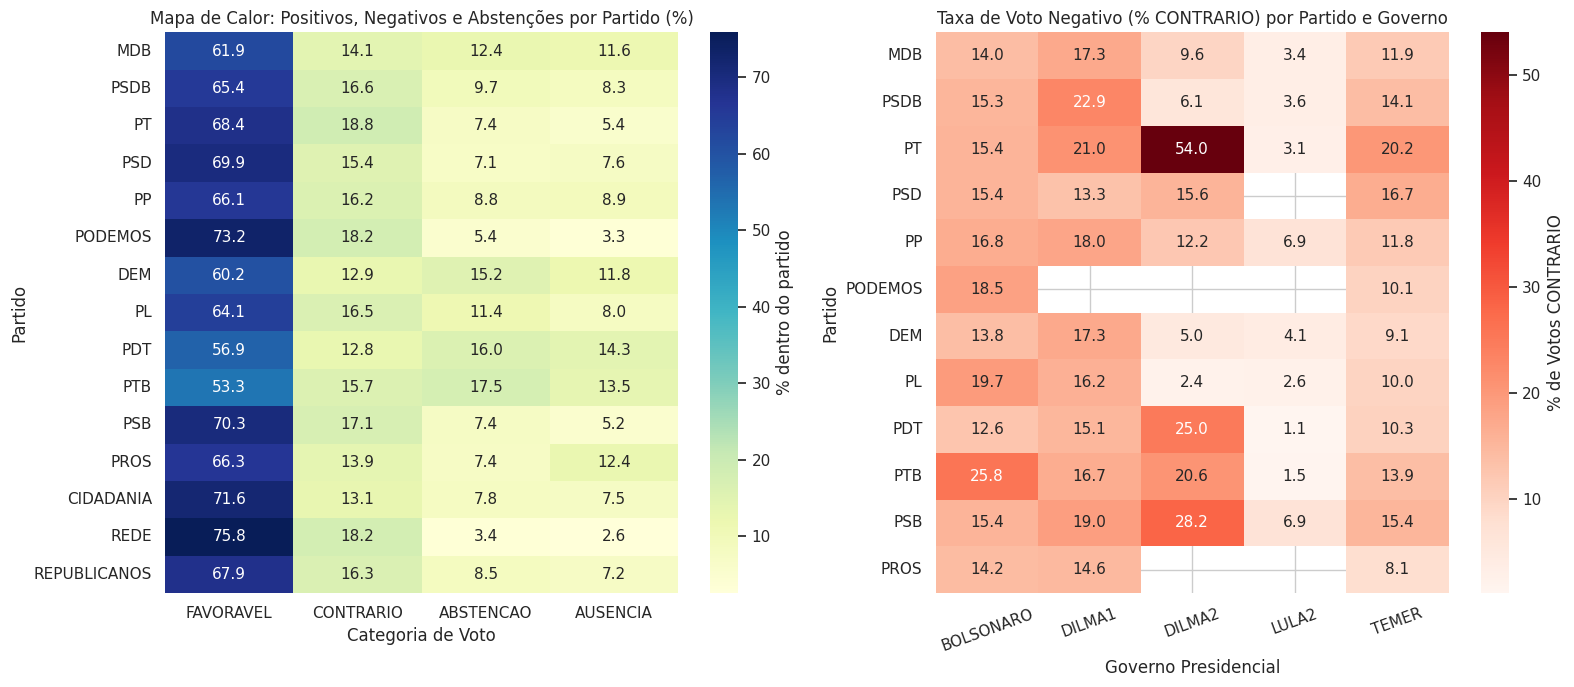

In [ ]:
# =============================================================================
# CÉLULA 2.8: EDA — HEATMAP PARTIDO × VOTO E INVERSÃO POR GOVERNO PRESIDENCIAL
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Heatmap Partido × Categoria de Voto (%)
sns.heatmap(
    ct_pct.iloc[::-1],
    annot=True, fmt=".1f", cmap="YlGnBu",
    cbar_kws={"label": "% dentro do partido"}, ax=axes[0]
)
axes[0].set_title("Mapa de Calor: Positivos, Negativos e Abstenções por Partido (%)")
axes[0].set_xlabel("Categoria de Voto")
axes[0].set_ylabel("Partido")

# 2. Heatmap Taxa de Voto Negativo (% CONTRARIO) por Partido × Governo
df_top12 = df[df["sigla_partido"].isin(top15_partidos[:12])].copy()
df_top12["is_contrario"] = (df_top12["categoria_voto"] == "CONTRARIO").astype(float) * 100.0
piv_gov_con = (
    df_top12.pivot_table(
        index="sigla_partido", columns="governo",
        values="is_contrario", aggfunc="mean"
    ).reindex(index=top15_partidos[:12])
)
sns.heatmap(
    piv_gov_con,
    annot=True, fmt=".1f", cmap="Reds",
    cbar_kws={"label": "% de Votos CONTRARIO"}, ax=axes[1]
)
axes[1].set_title("Taxa de Voto Negativo (% CONTRARIO) por Partido e Governo")
axes[1].set_xlabel("Governo Presidencial")
axes[1].set_ylabel("Partido")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

---
## Célula 3: Processamento de Linguagem Natural (PLN / SBERT) e PCA Causal
### 3.1 Extração de Ementas por Matéria (`sk_materia`) e Varredura de Vazamento Léxico (`LEAK_RE`)
Seleção do campo textual `ementa` da tabela `dim_materia` (agrupado por `sk_materia`) e auditoria léxica pré-codificação para quantificar menções a radicais de aprovação ou rejeição (**ERRO-03**).

In [ ]:
# =============================================================================
# CÉLULA 3.1: SELEÇÃO DE EMENTAS POR MATÉRIA E VARREDURA DE LEAKAGE DE TEXTO
# =============================================================================
EMBED_CACHE_FILE = "embeddings_materia_2010_2022.npy"
EMBED_IDS_FILE   = "embeddings_materia_ids_2010_2022.npy"

# Campo embeddado: ementa da matéria (dim_materia), indexada por sk_materia.
# A ementa descreve o conteúdo da proposição e é anterior à deliberação, ao
# contrário de texto_completo_votacao (descrição da sessão de votação).
if "ementa" in df.columns:
    campo_texto = "ementa"
else:
    # LIMITAÇÃO: sem ementa no DW, recai-se sobre texto_completo_votacao, que
    # descreve a sessão e pode conter menções ao resultado (risco de leakage).
    campo_texto = "texto_completo_votacao"

# Extração de textos únicos por matéria legislativa
df_textos = df[["sk_materia", campo_texto]].drop_duplicates("sk_materia")

# Varredura de leakage de texto antes do encode
LEAK_RE = r'aprovad|rejeitad|aprovação|rejeição'
n_leak = (
    df_textos[campo_texto].fillna('').str.lower()
    .str.contains(LEAK_RE, regex=True).sum()
)
print(f'⚠ Textos com menção ao resultado: {n_leak:,}')

textos_unicos = df_textos[campo_texto].fillna("").astype(str).tolist()
ids_unicos = df_textos["sk_materia"].astype(int).tolist()
print(f"✓ Matérias únicas preparadas para vetorização ({campo_texto}): {len(textos_unicos):,}")

⚠ Textos com menção ao resultado: 6
✓ Matérias únicas preparadas para vetorização (ementa): 489


### 3.2 Codificação Semântica Sentence-BERT (`384d`), Cache em Disco e Dicionário `embed_dict_raw`
Vetorização das ementas legislativas com o modelo multilíngue `paraphrase-multilingual-MiniLM-L12-v2`, persistência em `embeddings_materia_2010_2022.npy` e indexação por `int(sk_materia)`.

In [ ]:
# =============================================================================
# CÉLULA 3.2: CODIFICAÇÃO SBERT (384D), CACHE LOCAL E DICIONÁRIO POR MATÉRIA
# =============================================================================
if os.path.exists(EMBED_CACHE_FILE) and os.path.exists(EMBED_IDS_FILE):
    print("✓ Carregando embeddings SBERT pré-computados do cache local...")
    embeddings_raw = np.load(EMBED_CACHE_FILE)
    ids_cached = np.load(EMBED_IDS_FILE)
else:
    print(f"Codificando {len(textos_unicos):,} textos legislativos ({campo_texto}) com {EMBED_MODEL_NAME}...")
    sbert_model = SentenceTransformer(EMBED_MODEL_NAME)
    embeddings_raw = sbert_model.encode(
        textos_unicos,
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True
    )
    np.save(EMBED_CACHE_FILE, embeddings_raw)
    np.save(EMBED_IDS_FILE, np.array(ids_unicos))
    ids_cached = np.array(ids_unicos)

RAW_EMBED_DIM = embeddings_raw.shape[1]
embed_dict_raw = {int(sk_materia): vec for sk_materia, vec in zip(ids_cached, embeddings_raw)}
print(f"✓ Embeddings SBERT prontos: {len(embed_dict_raw):,} matérias × {RAW_EMBED_DIM} dimensões (campo: {campo_texto}).")

✓ Carregando embeddings SBERT pré-computados do cache local...
✓ Embeddings SBERT prontos: 489 matérias × 384 dimensões (campo: ementa).


### 3.3 Função de Redução Dimensional Causal por Dobra (`extract_causal_pca_embeddings`)
Projeção dos vetores densos de 384 dimensões em `PCA_N_COMPONENTS = 50` componentes principais ortogonais, ajustada exclusivamente sobre o conjunto de treino de cada dobra.

In [ ]:
# =============================================================================
# CÉLULA 3.3: FUNÇÃO DE REDUÇÃO DIMENSIONAL CAUSAL (PCA POR DOBRA)
# =============================================================================
def extract_causal_pca_embeddings(train_materia_ids: pd.Series,
                                  test_materia_ids: pd.Series,
                                  n_components: int = PCA_N_COMPONENTS):
    """
    Mapeia os vetores SBERT brutos (indexados por sk_materia) para treino e teste
    e aplica redução dimensional via PCA ajustada exclusivamente sobre o treino.
    """
    X_emb_train_raw = np.vstack([
        embed_dict_raw.get(int(mid), np.zeros(RAW_EMBED_DIM))
        for mid in train_materia_ids
    ])
    X_emb_test_raw = np.vstack([
        embed_dict_raw.get(int(mid), np.zeros(RAW_EMBED_DIM))
        for mid in test_materia_ids
    ])

    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    X_emb_train_pca = pca.fit_transform(X_emb_train_raw)
    X_emb_test_pca  = pca.transform(X_emb_test_raw)

    var_explicada = float(pca.explained_variance_ratio_.sum())
    return X_emb_train_pca, X_emb_test_pca, var_explicada


print(f"✓ Função extract_causal_pca_embeddings definida (PCA_N_COMPONENTS={PCA_N_COMPONENTS}).")

✓ Função extract_causal_pca_embeddings definida (PCA_N_COMPONENTS=50).


---
## Célula 4: Engenharia de Atributos, Médias Móveis Causais e Espaço Latente (`TruncatedSVD`)
### 4.1 Histórico Comportamental Causal por Senador (`shift(1).rolling`)
Ordenação cronológica estrita por senador (`['sk_senador', 'data_completa', 'sk_votacao']`) e cálculo das médias móveis causais:
- `hist_disc_partido`: taxa de alinhamento com o voto modal do próprio partido nas últimas 30 votações;
- `hist_taxa_fav`: taxa pessoal de votos `FAVORAVEL` (`P(FAVORAVEL)`) nas últimas 30 votações (**ERRO-11**);
- `hist_fidelidade_bloco`: alinhamento real com a orientação da coalizão (`BASE → FAVORAVEL`, `OPOSICAO → CONTRARIO`).

In [ ]:
# =============================================================================
# CÉLULA 4.1: HISTÓRICO COMPORTAMENTAL CAUSAL POR SENADOR (SHIFT(1).ROLLING)
# =============================================================================
WINDOW_HIST = 30
MIN_PERIODS_HIST = 5
FALLBACK_NEUTRO = 0.5

# Ordenação cronológica estrita por senador para cálculo causal de janelas móveis
df = df.sort_values(["sk_senador", "data_completa", "sk_votacao"]).reset_index(drop=True)

# 1. Indicadores instantâneos (usados exclusivamente com shift(1) para evitar leakage)
voto_modal_partido = (
    df.groupby(["sk_votacao", "sigla_partido"])["categoria_voto"]
    .transform(lambda s: (s == s.mode().iloc[0]).astype(float))
)
df["_voto_com_partido"] = voto_modal_partido
df["_voto_favoravel"]   = (df["categoria_voto"] == "FAVORAVEL").astype(float)

coalizao_norm = df["situacao_coalizao"].astype(str).str.strip().str.upper()
df["_fiel_bloco"] = np.select(
    condlist=[coalizao_norm == "BASE", coalizao_norm == "OPOSICAO"],
    choicelist=[
        (df["categoria_voto"] == "FAVORAVEL").astype(float),
        (df["categoria_voto"] == "CONTRARIO").astype(float)
    ],
    default=np.nan
)

# 2. Médias móveis causais por senador (shift(1) garante uso exclusivo do passado)
#    • hist_taxa_fav: P(FAVORAVEL) pessoal do senador. NÃO mede governismo — um
#      senador de oposição pode ter alta taxa favorável em pautas consensuais.
#    • hist_fidelidade_bloco: alinhamento real com a coalizão (BASE→FAVORAVEL,
#      OPOSICAO→CONTRARIO); é esta a medida de governismo/oposicionismo.
for col_src, col_dst in [
    ("_voto_com_partido", "hist_disc_partido"),
    ("_voto_favoravel",   "hist_taxa_fav"),
    ("_fiel_bloco",       "hist_fidelidade_bloco")
]:
    df[col_dst] = (
        df.groupby("sk_senador")[col_src]
        .transform(lambda x: x.shift(1).rolling(WINDOW_HIST, min_periods=MIN_PERIODS_HIST).mean())
        .fillna(FALLBACK_NEUTRO)
    )

df.drop(columns=["_voto_com_partido", "_voto_favoravel", "_fiel_bloco"], inplace=True)
print("✓ Médias móveis causais calculadas: ['hist_disc_partido', 'hist_taxa_fav', 'hist_fidelidade_bloco'].")

✓ Médias móveis causais calculadas: ['hist_disc_partido', 'hist_taxa_fav', 'hist_fidelidade_bloco'].


### 4.2 Senioridade Parlamentar, Codificação Cíclica Sazonal e Decomposição de Emendas
Cálculo causal em $O(N)$ de legislaturas anteriores exercidas (`senioridade`), transformação trigonométrica de `mes` e `trimestre` (**ERRO-08**) e decomposição da variável zero-inflada `n_emendas_autor` em `flag_tem_emenda` e `log_emendas` (**ERRO-09**).

In [ ]:
# =============================================================================
# CÉLULA 4.2: SENIORIDADE, CALENDÁRIO CÍCLICO (ERRO-08) E EMENDAS (ERRO-09)
# =============================================================================
def _causal_distinct_count(s: pd.Series) -> np.ndarray:
    """Conta legislaturas distintas anteriores exercidas pelo senador em O(N) causal."""
    out = np.zeros(len(s), dtype=float)
    seen = set()
    for i, val in enumerate(s.to_numpy()):
        out[i] = float(len(seen))
        seen.add(val)
    return out

df["senioridade"] = df.groupby("sk_senador")["numero_legislatura"].transform(_causal_distinct_count)

# Codificação cíclica do calendário (evita descontinuidade dez→jan e T4→T1)
df['mes_sin'] = np.sin(2 * np.pi * df['mes'] / 12)
df['mes_cos'] = np.cos(2 * np.pi * df['mes'] / 12)
df['tri_sin'] = np.sin(2 * np.pi * df['trimestre'] / 4)
df['tri_cos'] = np.cos(2 * np.pi * df['trimestre'] / 4)

# Decomposição da variável zero-inflada n_emendas_autor
df['flag_tem_emenda'] = (df['n_emendas_autor'] > 0).astype(int)
df['log_emendas']     = np.log1p(df['n_emendas_autor'])

print("✓ Atributos derivados criados: ['senioridade', 'mes_sin', 'mes_cos', 'tri_sin', 'tri_cos', 'flag_tem_emenda', 'log_emendas'].")

✓ Atributos derivados criados: ['senioridade', 'mes_sin', 'mes_cos', 'tri_sin', 'tri_cos', 'flag_tem_emenda', 'log_emendas'].


### 4.3 Coordenadas Espaciais via `TruncatedSVD` Causal Sem Vazamento (`extract_causal_svd_coords`)
Decomposição da matriz de votação nominal $\mathbf{A} \in \{-1, 0, +1\}$ ajustada no conjunto de treino de cada dobra, com **subtração vetorizada da contribuição do voto corrente** ($\mathbf{c}_{i,-j} = \mathbf{c}_i - a_{ij}\mathbf{V}_{r,:,j}$) nas linhas de treino (**ERRO-02**).

In [ ]:
# =============================================================================
# CÉLULA 4.3: COORDENADAS ESPACIAIS VIA TRUNCATEDSVD SEM VAZAMENTO (ERRO-02)
# =============================================================================
VOTO_ESCALAR_SVD = {"FAVORAVEL": 1.0, "CONTRARIO": -1.0, "ABSTENCAO": 0.0, "AUSENCIA": 0.0}

def extract_causal_svd_coords(df_train: pd.DataFrame,
                              df_test: pd.DataFrame,
                              n_components: int = SVD_N_COMPONENTS):
    """
    Decompõe a matriz de alinhamento parlamentar A in {-1, 0, +1} via TruncatedSVD
    ajustada estritamente sobre o conjunto de treino da dobra.

    Linhas de TREINO: a coordenada c_i = A[i, :] @ V_r^T inclui o próprio voto
    corrente a_ij. Para eliminar esse vazamento, subtrai-se a sua contribuição:
        c_ij = c_i - a_ij * V_r[:, j]
    onde V_r são os vetores singulares à direita (svd.components_) e a_ij é o
    valor escalar do voto corrente na coluna j (sk_votacao) da matriz pivot.

    Linhas de TESTE: sem alteração (projeção do treino ou vetor neutro na origem
    para senadores novatos).
    """
    votos_tr = df_train["categoria_voto"].map(VOTO_ESCALAR_SVD).fillna(0.0)
    pivot_tr = (
        df_train.assign(_v=votos_tr)
        .pivot_table(index="sk_senador", columns="sk_votacao", values="_v",
                     aggfunc="mean", fill_value=0.0)
    )
    n_comp_eff = min(n_components, max(1, min(pivot_tr.shape) - 1))
    svd = TruncatedSVD(n_components=n_comp_eff, random_state=RANDOM_STATE)
    coords_matrix = svd.fit_transform(pivot_tr.values)
    V_r = svd.components_                      # (n_comp_eff, n_votacoes_treino)

    coord_map = dict(zip(pivot_tr.index, coords_matrix))
    col_idx_map = {vot_id: idx for idx, vot_id in enumerate(pivot_tr.columns)}
    zero_vec = np.zeros(n_comp_eff)

    # TREINO: subtração vetorizada da contribuição do voto corrente
    sen_arr = df_train["sk_senador"].values
    vot_arr = df_train["sk_votacao"].values
    aij_arr = votos_tr.values.astype(float)

    X_svd_train = np.array([coord_map.get(s, zero_vec) for s in sen_arr], dtype=float)
    j_arr = np.array([col_idx_map.get(v, -1) for v in vot_arr], dtype=int)
    valid = j_arr >= 0
    X_svd_train[valid] -= aij_arr[valid, np.newaxis] * V_r[:, j_arr[valid]].T

    # TESTE: sem alteração
    X_svd_test = np.vstack([coord_map.get(s, zero_vec) for s in df_test["sk_senador"]])
    svd_cols = [f"svd_coord_{i+1}" for i in range(n_comp_eff)]

    return X_svd_train, X_svd_test, svd_cols


print(f"✓ Função extract_causal_svd_coords definida (SVD_N_COMPONENTS={SVD_N_COMPONENTS}).")

✓ Função extract_causal_svd_coords definida (SVD_N_COMPONENTS=2).


### 4.4 Consolidação de `NUMERIC_FEATURES` e `CATEGORICAL_FEATURES`
Definição final das listas de atributos numéricos (sem `flag_base_aliada`, `mes`, `trimestre` e `n_emendas_autor` — **ERRO-07**, **ERRO-08**, **ERRO-09**, **ERRO-11**) e categóricos (codificados com `OneHotEncoder` dentro de cada dobra).

In [ ]:
# =============================================================================
# CÉLULA 4.4: DEFINIÇÃO DE NUMERIC_FEATURES E CATEGORICAL_FEATURES
# =============================================================================
# flag_base_aliada permanece no DataFrame, mas NÃO entra como feature direta:
# o valor 0 colapsa OPOSICAO e INDEPENDENTE; situacao_coalizao (OHE) já distingue.
NUMERIC_FEATURES = [
    "mes_sin",
    "mes_cos",
    "tri_sin",
    "tri_cos",
    "ano_legislatura",
    "eh_projeto_lei",
    "eh_orcamento",
    "flag_tem_emenda",
    "log_emendas",
    "hist_disc_partido",
    "hist_taxa_fav",
    "hist_fidelidade_bloco",
    "senioridade"
]

CATEGORICAL_FEATURES = [
    "sigla_partido",
    "uf",
    "regiao",
    "sexo",
    "situacao_coalizao",
    "categoria_tematica",
    "tipo_materia"
]

print("✓ Engenharia de atributos concluída.")
print(f"  • Atributos numéricos/históricos ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"  • Atributos categóricos para One-Hot Encoding ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")

✓ Engenharia de atributos concluída.
  • Atributos numéricos/históricos (13): ['mes_sin', 'mes_cos', 'tri_sin', 'tri_cos', 'ano_legislatura', 'eh_projeto_lei', 'eh_orcamento', 'flag_tem_emenda', 'log_emendas', 'hist_disc_partido', 'hist_taxa_fav', 'hist_fidelidade_bloco', 'senioridade']
  • Atributos categóricos para One-Hot Encoding (7): ['sigla_partido', 'uf', 'regiao', 'sexo', 'situacao_coalizao', 'categoria_tematica', 'tipo_materia']


---
## Célula 5: Configuração da Validação Temporal (Walk-Forward)
### 5.1 Definição das 4 Dobras (`F1–F4`) em Janela Expansiva
Configuração do protocolo *walk-forward* em 4 dobras com conjuntos de treino estritamente crescentes (`F1 ⊂ F2 ⊂ F3 ⊂ F4`) e janelas bienais de teste alternando períodos de transição e continuidade legislativa (**ERRO-01**).

In [ ]:
# =============================================================================
# CÉLULA 5.1: DEFINIÇÃO DAS 4 DOBRAS EM JANELA EXPANSIVA (ERRO-01)
# =============================================================================
# Janela expansiva: o treino acumula todo o passado; o teste é o biênio seguinte.
# F1/F3 = transição de legislatura; F2/F4 = continuidade.
FOLDS = [
    {
        "id": "F1",
        "nome": "F1 (2010–2014 -> 2015–2016)",
        "descricao": "Treino: 2010–2014 | Teste: 2015–2016 (Transição 54ª->55ª)",
        "train_mask": df["ano"] <= 2014,
        "test_mask":  df["ano"].between(2015, 2016)
    },
    {
        "id": "F2",
        "nome": "F2 (2010–2016 -> 2017–2018)",
        "descricao": "Treino: 2010–2016 | Teste: 2017–2018 (Continuidade 55ª)",
        "train_mask": df["ano"] <= 2016,
        "test_mask":  df["ano"].between(2017, 2018)
    },
    {
        "id": "F3",
        "nome": "F3 (2010–2018 -> 2019–2020)",
        "descricao": "Treino: 2010–2018 | Teste: 2019–2020 (Transição 55ª->56ª)",
        "train_mask": df["ano"] <= 2018,
        "test_mask":  df["ano"].between(2019, 2020)
    },
    {
        "id": "F4",
        "nome": "F4 (2010–2020 -> 2021–2022)",
        "descricao": "Treino: 2010–2020 | Teste: 2021–2022 (Continuidade 56ª)",
        "train_mask": df["ano"] <= 2020,
        "test_mask":  df["ano"].between(2021, 2022)
    }
]

print("✓ Protocolo Walk-Forward configurado (janela expansiva):")
for f in FOLDS:
    n_tr, n_te = f["train_mask"].sum(), f["test_mask"].sum()
    max_dt_tr = df.loc[f["train_mask"], "data_completa"].max()
    min_dt_te = df.loc[f["test_mask"],  "data_completa"].min()
    assert max_dt_tr < min_dt_te, f"Vazamento temporal em {f['id']}: {max_dt_tr} >= {min_dt_te}"
    print(f"  • {f['nome']}: Treino={n_tr:,} votos | Teste={n_te:,} votos ({f['descricao']})")

# Verificação da janela expansiva: cada treino contém estritamente o anterior
for f_prev, f_next in zip(FOLDS[:-1], FOLDS[1:]):
    assert not (f_prev["train_mask"] & ~f_next["train_mask"]).any(), \
        f"{f_prev['id']} não está contido em {f_next['id']}"
    assert f_next["train_mask"].sum() > f_prev["train_mask"].sum(), \
        f"Treino de {f_next['id']} não é maior que o de {f_prev['id']}"
print("✓ Treinos estritamente crescentes (F1 ⊂ F2 ⊂ F3 ⊂ F4).")

✓ Protocolo Walk-Forward configurado (janela expansiva):
  • F1 (2010–2014 -> 2015–2016): Treino=18,943 votos | Teste=1,385 votos (Treino: 2010–2014 | Teste: 2015–2016 (Transição 54ª->55ª))
  • F2 (2010–2016 -> 2017–2018): Treino=20,328 votos | Teste=7,736 votos (Treino: 2010–2016 | Teste: 2017–2018 (Continuidade 55ª))
  • F3 (2010–2018 -> 2019–2020): Treino=28,064 votos | Teste=14,535 votos (Treino: 2010–2018 | Teste: 2019–2020 (Transição 55ª->56ª))
  • F4 (2010–2020 -> 2021–2022): Treino=42,599 votos | Teste=17,505 votos (Treino: 2010–2020 | Teste: 2021–2022 (Continuidade 56ª))
✓ Treinos estritamente crescentes (F1 ⊂ F2 ⊂ F3 ⊂ F4).


### 5.2 Função Construtora de Matrizes por Dobra (`build_fold_matrices`)
Construção isolada das matrizes sem escalonamento (`X_train`, `X_test`, para árvores e Naive Bayes) e padronizadas na matriz completa (`X_train_scaled`, `X_test_scaled`, exclusivamente para `SVM` e `MLP` — **ERRO-04**), com tratamento seguro de NaNs (**ERRO-13**).

In [ ]:
# =============================================================================
# CÉLULA 5.2: FUNÇÃO BUILD_FOLD_MATRICES (ERRO-04 E ERRO-13)
# =============================================================================
def build_fold_matrices(df_full: pd.DataFrame, train_mask: pd.Series, test_mask: pd.Series):
    """
    Constrói as matrizes de uma dobra temporal, ajustando todos os transformadores
    estritamente sobre o conjunto de treino.

    Treino e teste são ordenados cronologicamente, de modo que os últimos 20% do
    treino (validação interna do tuning) correspondam ao período mais recente.

    Retorna:
        X_train, y_train, X_test, y_test       → matrizes sem escalonamento (árvores, GNB)
        X_train_scaled, X_test_scaled          → matriz completa padronizada (SVM, MLP)
        df_train, df_test, feature_names, var_pca
    """
    df_train = (df_full[train_mask].copy()
                .sort_values(["data_completa", "sk_votacao", "sk_senador"])
                .reset_index(drop=True))
    df_test  = (df_full[test_mask].copy()
                .sort_values(["data_completa", "sk_votacao", "sk_senador"])
                .reset_index(drop=True))

    # 1. Coordenadas espaciais latentes via TruncatedSVD (ajustadas só no treino)
    X_svd_train, X_svd_test, svd_cols = extract_causal_svd_coords(
        df_train, df_test, n_components=SVD_N_COMPONENTS
    )

    # 2. Variáveis numéricas + coordenadas SVD (sem escalonamento)
    X_num_train = np.hstack([df_train[NUMERIC_FEATURES].values.astype(float), X_svd_train])
    X_num_test  = np.hstack([df_test[NUMERIC_FEATURES].values.astype(float),  X_svd_test])

    # 3. Codificação One-Hot para variáveis categóricas nominais (fit só no treino)
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    X_cat_train = ohe.fit_transform(df_train[CATEGORICAL_FEATURES].astype(str))
    X_cat_test  = ohe.transform(df_test[CATEGORICAL_FEATURES].astype(str))
    ohe_cols = list(ohe.get_feature_names_out(CATEGORICAL_FEATURES))

    # 4. Redução dimensional causal (PCA) sobre os embeddings SBERT por matéria
    X_emb_train, X_emb_test, var_pca = extract_causal_pca_embeddings(
        df_train["sk_materia"],
        df_test["sk_materia"],
        n_components=PCA_N_COMPONENTS
    )
    emb_cols = [f"sbert_pca_{i}" for i in range(PCA_N_COMPONENTS)]

    # 5. Concatenação final das matrizes de treino e teste (sem escalonamento)
    X_train = np.hstack([X_num_train, X_cat_train, X_emb_train])
    X_test  = np.hstack([X_num_test,  X_cat_test,  X_emb_test])

    y_train = df_train["target"].values
    y_test  = df_test["target"].values

    feature_names = NUMERIC_FEATURES + svd_cols + ohe_cols + emb_cols

    # 6. Tratamento de NaNs (aviso + imputação em vez de interromper o loop)
    n_nan_tr = np.isnan(X_train).sum()
    n_nan_te = np.isnan(X_test).sum()
    if n_nan_tr > 0 or n_nan_te > 0:
        print(f'  ⚠ NaNs: treino={n_nan_tr}, teste={n_nan_te} → imputados com 0')
        X_train = np.nan_to_num(X_train, nan=0.0)
        X_test  = np.nan_to_num(X_test,  nan=0.0)

    # 7. Padronização da matriz COMPLETA, apenas para SVM e MLP (fit só no treino)
    scaler_svm_mlp = StandardScaler()
    X_train_scaled = scaler_svm_mlp.fit_transform(X_train)
    X_test_scaled  = scaler_svm_mlp.transform(X_test)

    return (X_train, y_train, X_test, y_test,
            X_train_scaled, X_test_scaled,
            df_train, df_test, feature_names, var_pca)


print("✓ Função build_fold_matrices pronta (retorna 10 objetos por dobra).")

✓ Função build_fold_matrices pronta (retorna 10 objetos por dobra).


---
## Célula 6: Treinamento, Tuning Temporal, Baselines e Avaliação dos Algoritmos
### 6.1 Definição do Painel de Classificadores Supervisionados Base (`get_base_classifiers`)
Instanciação dos 7 algoritmos supervisionados da literatura (`XGBoost`, `Random Forest`, `Decision Tree`, `MLP` com `max_iter=300` [**ERRO-15**], `SVM` com `probability=True` [**ERRO-05**], `LightGBM` e `Gaussian Naive Bayes`).

In [ ]:
# =============================================================================
# CÉLULA 6.1: PAINEL DE CLASSIFICADORES SUPERVISIONADOS BASE (ERRO-05 E ERRO-15)
# =============================================================================
# Modelos sensíveis à escala: recebem a matriz padronizada (X_train_scaled / X_test_scaled)
SCALED_MODELS = ("SVM", "MLP")


def get_base_classifiers():
    """Instancia os 7 algoritmos base da literatura com hiperparâmetros padrão."""
    return {
        "XGBoost": XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=0
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=8,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        "MLP": MLPClassifier(
            hidden_layer_sizes=(128, 64),
            max_iter=300,
            early_stopping=True,
            random_state=RANDOM_STATE
        ),
        "SVM": SVC(
            kernel="rbf",
            C=1.0,
            class_weight="balanced",
            probability=True,
            random_state=RANDOM_STATE
        ),
        # Balanceamento via sample_weight no fit (como no XGBoost). class_weight
        # não é usado aqui: o LightGBM multiplica class_weight × sample_weight.
        # n_jobs=1 evita contenção de threads OpenMP dentro do RandomizedSearchCV(n_jobs=-1).
        "LightGBM": LGBMClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbose=-1
        ),
        "Gaussian Naive Bayes": GaussianNB()
    }


print(f"✓ Classificadores configurados ({len(get_base_classifiers())}): {list(get_base_classifiers().keys())}")

✓ Classificadores configurados (7): ['XGBoost', 'Random Forest', 'Decision Tree', 'MLP', 'SVM', 'LightGBM', 'Gaussian Naive Bayes']


### 6.2 Avaliação em Nível Macro (`Bill-Level Accuracy`) e Quóruns Constitucionais (`evaluate_bill_level_accuracy`)
Agregação dos votos nominais previstos por sessão (`sk_votacao`) obedecendo aos quóruns constitucionais do Senado Federal: **49 votos favoráveis** para `PEC` ($3/5$ de 81), **41 votos favoráveis** para `PLP` (maioria absoluta de 81) e **maioria simples dos presentes** (`FAVORAVEL + CONTRARIO`) para as demais proposições (**ERRO-10**).

In [ ]:
# =============================================================================
# CÉLULA 6.2: AVALIAÇÃO MACRO E QUÓRUNS CONSTITUCIONAIS DO SENADO (ERRO-10)
# =============================================================================
QUORUM_SENADO = {
    'PEC': 49,   # 3/5 de 81
    'PLP': 41,   # maioria absoluta de 81
}
# Para PL, MPV e demais: maioria simples dos presentes (votantes = FAVORAVEL + CONTRARIO)


def evaluate_bill_level_accuracy(df_test_fold: pd.DataFrame, y_pred: np.ndarray) -> float:
    """
    Agrega as predições individuais por sessão (sk_votacao) para prever a aprovação
    ou rejeição da matéria, respeitando os quóruns constitucionais do Senado.
    """
    df_eval = df_test_fold[["sk_votacao", "resultado_votacao", "tipo_materia"]].copy()
    df_eval["voto_pred"] = le_target.inverse_transform(y_pred)

    acertos = []
    for _, grp in df_eval.groupby("sk_votacao"):
        res_raw = str(grp["resultado_votacao"].iloc[0]).strip().upper()
        if res_raw in ("A", "APROVADA", "APROVADO"):
            real_outcome = "A"
        elif res_raw in ("R", "REJEITADA", "REJEITADO"):
            real_outcome = "R"
        else:
            continue

        votantes = grp[grp['voto_pred'].isin(['FAVORAVEL', 'CONTRARIO'])]
        n_fav = (votantes['voto_pred'] == 'FAVORAVEL').sum()
        n_tot_votantes = len(votantes)
        if n_tot_votantes == 0:
            continue

        tipo = grp['tipo_materia'].iloc[0]
        limiar = QUORUM_SENADO.get(tipo, None)

        if limiar is not None:
            pred_outcome = 'A' if n_fav >= limiar else 'R'
        else:
            pred_outcome = 'A' if n_fav > n_tot_votantes / 2 else 'R'

        acertos.append(real_outcome == pred_outcome)

    return float(np.mean(acertos)) if acertos else np.nan


print(f"✓ Função evaluate_bill_level_accuracy definida (QUORUM_SENADO={QUORUM_SENADO}).")

✓ Função evaluate_bill_level_accuracy definida (QUORUM_SENADO={'PEC': 49, 'PLP': 41}).


### 6.3 Otimização Temporal de Hiperparâmetros (`RandomizedSearchCV` + `PredefinedSplit`)
Definição dos espaços de busca (`PARAM_SPACES`) para `XGBoost`, `LightGBM` e `Random Forest` e da função `tune_model`, utilizando os últimos 20% cronológicos do treino de cada dobra como validação temporal interna (**ERRO-12**).

In [ ]:
# =============================================================================
# CÉLULA 6.3: OTIMIZAÇÃO TEMPORAL DE HIPERPARÂMETROS (ERRO-12)
# =============================================================================
PARAM_SPACES = {
    'XGBoost': {
        'n_estimators': randint(100, 500),
        'max_depth': randint(3, 9),
        'learning_rate': loguniform(0.01, 0.3),
        'subsample': uniform(0.6, 0.4),
        'colsample_bytree': uniform(0.6, 0.4),
    },
    'LightGBM': {
        'n_estimators': randint(100, 500),
        'max_depth': randint(3, 9),
        'learning_rate': loguniform(0.01, 0.3),
        'num_leaves': randint(20, 100),
    },
    'Random Forest': {
        'n_estimators': randint(100, 400),
        'max_depth': [None, 8, 15],
        'max_features': ['sqrt', 'log2'],
    },
}
N_ITER = 25


def tune_model(name, clf, X_tr, y_tr, sw=None):
    """
    RandomizedSearchCV com validação temporal interna (últimos 20% do treino,
    que está ordenado cronologicamente). Com refit=True, o estimador retornado
    já está ajustado no treino completo da dobra.
    """
    if name not in PARAM_SPACES:
        return clf
    # Últimos 20% do treino como validação temporal interna
    n = len(X_tr)
    fold_idx = np.where(np.arange(n) >= int(n * 0.8), 0, -1)
    ps = PredefinedSplit(fold_idx)
    rscv = RandomizedSearchCV(
        clf, PARAM_SPACES[name],
        n_iter=N_ITER, scoring='f1_macro',
        cv=ps, refit=True, n_jobs=-1,
        random_state=RANDOM_STATE, error_score=0.0
    )
    fit_kw = {'sample_weight': sw} if sw is not None else {}
    rscv.fit(X_tr, y_tr, **fit_kw)
    print(f'    {name}: best F1={rscv.best_score_:.4f}')
    return rscv.best_estimator_


print(f"✓ Função tune_model configurada (N_ITER={N_ITER}, modelos={list(PARAM_SPACES.keys())}).")

✓ Função tune_model configurada (N_ITER=25, modelos=['XGBoost', 'LightGBM', 'Random Forest']).


### 6.4 Pré-Computação das Matrizes das 4 Dobras (`cache_dobras`) e Avaliação dos 4 Baselines (`A`, `C`, `D`, `E`)
Para evitar *timeout* no Google Colab, construímos uma única vez as matrizes das 4 dobras (`F1–F4`) em `cache_dobras`, avaliamos imediatamente os 4 baselines (**Baseline A**: Classe Majoritária; **Baseline C**: Moda do Partido; **Baseline D**: Persistência do Senador; **Baseline E**: Coalizão Direta — **ERRO-06**) e definimos `executar_modelo_nas_dobras(model_name)` com salvamento incremental em `resultados_checkpoint.csv`. Assim, cada algoritmo roda na sua própria célula (`6.5` a `6.11`).

In [ ]:
# =============================================================================
# CÉLULA 6.4: PRÉ-COMPUTAÇÃO DAS 4 DOBRAS + BASELINES (A, C, D, E) + HELPER POR MODELO
# =============================================================================
CHECKPOINT_CSV = "resultados_checkpoint.csv"

resultados_gerais = []
classification_reports = {}
predicoes_fold = {}
dados_teste_fold = {}
cache_dobras = {}


def _registrar_resultado(fold_nome, modelo, y_true, y_pred, df_te_fold, elapsed):
    """Calcula as métricas micro, macro e taxas de erro e atualiza resultados_gerais (idempotente)."""
    global resultados_gerais
    # Remove registro anterior do mesmo (Dobra, Modelo) caso a célula do modelo seja reexecutada
    resultados_gerais = [
        r for r in resultados_gerais
        if not (r["Dobra"] == fold_nome and r["Modelo"] == modelo)
    ]

    acc      = accuracy_score(y_true, y_pred)
    err_mic  = 1.0 - acc
    f1_mac   = f1_score(y_true, y_pred, average="macro", zero_division=0)
    f1_wei   = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    mcc      = matthews_corrcoef(y_true, y_pred)
    bill_acc = evaluate_bill_level_accuracy(df_te_fold, y_pred)
    err_mac  = (1.0 - bill_acc) if not np.isnan(bill_acc) else np.nan

    resultados_gerais.append({
        "Dobra": fold_nome,
        "Modelo": modelo,
        "Acurácia Micro": round(acc, 4),
        "Taxa de Erro Micro": round(err_mic, 4),
        "F1-Macro": round(f1_mac, 4),
        "F1-Weighted": round(f1_wei, 4),
        "MCC": round(mcc, 4),
        "Acurácia Macro (Bill)": round(bill_acc, 4) if not np.isnan(bill_acc) else np.nan,
        "Taxa de Erro Macro (Bill)": round(err_mac, 4) if not np.isnan(err_mac) else np.nan,
        "Tempo (s)": round(elapsed, 2)
    })
    print(f"  • {modelo:34s} | Acc={acc:.4f} (Erro={err_mic:.4f}) | F1-Macro={f1_mac:.4f} | "
          f"MCC={mcc:.4f} | Bill-Acc={bill_acc:.4f} ({elapsed:.1f}s)")


def executar_modelo_nas_dobras(model_name: str):
    """
    Treina/otimiza e avalia um único algoritmo nas 4 dobras pré-computadas em cache_dobras,
    salvando checkpoint incremental em disco ao final para evitar perda por timeout no Colab.
    """
    print(f"{'=' * 78}")
    print(f"TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: {model_name}")
    print(f"{'=' * 78}")

    for fold in FOLDS:
        fid = fold["id"]
        d = cache_dobras[fid]
        X_tr, y_tr, X_te, y_te = d["X_tr"], d["y_tr"], d["X_te"], d["y_te"]
        X_tr_scaled, X_te_scaled = d["X_tr_scaled"], d["X_te_scaled"]
        df_te = d["df_te"]
        sample_weights = d["sample_weights"]

        clf = get_base_classifiers()[model_name]
        t0 = time.time()

        if model_name in SCALED_MODELS:
            X_tr_use, X_te_use = X_tr_scaled, X_te_scaled
        else:
            X_tr_use, X_te_use = X_tr, X_te

        sw_use = sample_weights if model_name in ("XGBoost", "LightGBM") else None

        print(f"\n[{fold['nome']}]")
        if model_name in PARAM_SPACES:
            # refit=True: o best_estimator_ já sai ajustado no treino completo
            clf = tune_model(model_name, clf, X_tr_use, y_tr, sw=sw_use)
        else:
            # DT, SVM, MLP e GNB: hiperparâmetros padrão, ajuste único
            clf.fit(X_tr_use, y_tr)

        elapsed = time.time() - t0
        y_pred = clf.predict(X_te_use)

        predicoes_fold[(fid, model_name)] = y_pred
        _registrar_resultado(fold["nome"], model_name, y_te, y_pred, df_te, elapsed)

        classification_reports[(fold["nome"], model_name)] = classification_report(
            y_te, y_pred, labels=np.arange(len(le_target.classes_)),
            target_names=le_target.classes_, zero_division=0, output_dict=True
        )

    pd.DataFrame(resultados_gerais).to_csv(CHECKPOINT_CSV, index=False)
    print(f"\n✓ {model_name} concluído nas 4 dobras (checkpoint salvo em '{CHECKPOINT_CSV}').")


# ── Pré-computação das matrizes das 4 dobras e cálculo dos 4 Baselines ──────
for fold in FOLDS:
    fid = fold["id"]
    print(f"\n{'=' * 78}")
    print(f"Preparando matrizes e Baselines — {fold['nome']} ({fold['descricao']})")
    print(f"{'=' * 78}")

    (X_tr, y_tr, X_te, y_te,
     X_tr_scaled, X_te_scaled,
     df_tr, df_te, feat_names, var_pca) = build_fold_matrices(
        df, fold["train_mask"], fold["test_mask"]
    )
    sample_weights = compute_sample_weight(class_weight="balanced", y=y_tr)

    cache_dobras[fid] = {
        "X_tr": X_tr, "y_tr": y_tr,
        "X_te": X_te, "y_te": y_te,
        "X_tr_scaled": X_tr_scaled, "X_te_scaled": X_te_scaled,
        "df_tr": df_tr, "df_te": df_te,
        "feat_names": feat_names, "var_pca": var_pca,
        "sample_weights": sample_weights,
    }
    dados_teste_fold[fid] = (df_te, y_te)
    print(f"Dimensão das matrizes: Treino={X_tr.shape} | Teste={X_te.shape} | Variância PCA={var_pca:.2%}")

    # Baseline A: classe majoritária do treino
    maj_class = np.bincount(y_tr).argmax()
    y_pred_ba = np.full_like(y_te, maj_class)

    # Baseline C: moda do partido no treino
    mode_partido = (df_tr.groupby('sigla_partido')['categoria_voto']
                    .agg(lambda x: x.mode()[0]).to_dict())
    fb = df_tr['categoria_voto'].mode()[0]
    y_pred_bc = le_target.transform(
        df_te['sigla_partido'].map(mode_partido).fillna(fb))

    # Baseline D: persistência — moda recente do senador
    mode_sen = (df_tr.groupby('sk_senador')['categoria_voto']
                .agg(lambda x: x.mode()[0]).to_dict())
    y_pred_bd = le_target.transform(
        df_te['sk_senador'].map(mode_sen).fillna(fb))

    # Baseline E: coalizão direta
    coal_map = {'BASE': 'FAVORAVEL', 'OPOSICAO': 'CONTRARIO',
                'INDEPENDENTE': 'FAVORAVEL', 'DESCONHECIDO': fb}
    coal_te = df_te['situacao_coalizao'].astype(str).str.strip().str.upper()
    y_pred_be = le_target.transform(coal_te.map(coal_map).fillna(fb))

    for bl_name, y_pred_bl in [
        ("Baseline A (Classe Majoritária)", y_pred_ba),
        ("Baseline C (Moda do Partido)",    y_pred_bc),
        ("Baseline D (Persistência)",       y_pred_bd),
        ("Baseline E (Coalizão Direta)",    y_pred_be),
    ]:
        predicoes_fold[(fid, bl_name)] = y_pred_bl
        _registrar_resultado(fold["nome"], bl_name, y_te, y_pred_bl, df_te, 0.0)

pd.DataFrame(resultados_gerais).to_csv(CHECKPOINT_CSV, index=False)
print(f"\n✓ Matrizes das 4 dobras em cache e 4 Baselines avaliados (checkpoint: '{CHECKPOINT_CSV}').")


Preparando matrizes e Baselines — F1 (2010–2014 -> 2015–2016) (Treino: 2010–2014 | Teste: 2015–2016 (Transição 54ª->55ª))
Dimensão das matrizes: Treino=(18943, 141) | Teste=(1385, 141) | Variância PCA=91.93%
  • Baseline A (Classe Majoritária)    | Acc=0.6282 (Erro=0.3718) | F1-Macro=0.1929 | MCC=0.0000 | Bill-Acc=0.7727 (0.0s)
  • Baseline C (Moda do Partido)       | Acc=0.6130 (Erro=0.3870) | F1-Macro=0.2164 | MCC=0.0231 | Bill-Acc=0.6818 (0.0s)
  • Baseline D (Persistência)          | Acc=0.5783 (Erro=0.4217) | F1-Macro=0.2069 | MCC=-0.0080 | Bill-Acc=0.6818 (0.0s)
  • Baseline E (Coalizão Direta)       | Acc=0.4708 (Erro=0.5292) | F1-Macro=0.1942 | MCC=-0.0940 | Bill-Acc=0.6818 (0.0s)

Preparando matrizes e Baselines — F2 (2010–2016 -> 2017–2018) (Treino: 2010–2016 | Teste: 2017–2018 (Continuidade 55ª))
Dimensão das matrizes: Treino=(20328, 149) | Teste=(7736, 149) | Variância PCA=91.13%
  • Baseline A (Classe Majoritária)    | Acc=0.5906 (Erro=0.4094) | F1-Macro=0.1857 | MCC=0.00

### 6.5 Treinamento e Avaliação — Algoritmo 1: `XGBoost` (com Tuning Temporal)
Execução isolada do `XGBClassifier` nas 4 dobras (`F1–F4`), com `RandomizedSearchCV` (`PredefinedSplit` nos últimos 20% cronológicos do treino) e pesos balanceados por amostra (`sample_weight`).

In [ ]:
# =============================================================================
# CÉLULA 6.5: EXECUÇÃO ISOLADA — XGBOOST (4 DOBRAS COM TUNING TEMPORAL)
# =============================================================================
executar_modelo_nas_dobras("XGBoost")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: XGBoost

[F1 (2010–2014 -> 2015–2016)]
    XGBoost: best F1=0.4734
  • XGBoost                            | Acc=0.3697 (Erro=0.6303) | F1-Macro=0.2045 | MCC=-0.0234 | Bill-Acc=0.6818 (27.6s)

[F2 (2010–2016 -> 2017–2018)]
    XGBoost: best F1=0.4028
  • XGBoost                            | Acc=0.3482 (Erro=0.6518) | F1-Macro=0.2745 | MCC=0.0768 | Bill-Acc=0.5179 (26.6s)

[F3 (2010–2018 -> 2019–2020)]
    XGBoost: best F1=0.4329
  • XGBoost                            | Acc=0.5495 (Erro=0.4505) | F1-Macro=0.2844 | MCC=0.0662 | Bill-Acc=0.7933 (37.7s)

[F4 (2010–2020 -> 2021–2022)]
    XGBoost: best F1=0.3804
  • XGBoost                            | Acc=0.4839 (Erro=0.5161) | F1-Macro=0.2831 | MCC=0.1077 | Bill-Acc=0.5662 (52.3s)

✓ XGBoost concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.6 Treinamento e Avaliação — Algoritmo 2: `LightGBM` (com Tuning Temporal)
Execução isolada do `LGBMClassifier` nas 4 dobras (`F1–F4`), com `RandomizedSearchCV` temporal e `sample_weight` balanceado.

In [ ]:
# =============================================================================
# CÉLULA 6.6: EXECUÇÃO ISOLADA — LIGHTGBM (4 DOBRAS COM TUNING TEMPORAL)
# =============================================================================
executar_modelo_nas_dobras("LightGBM")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: LightGBM

[F1 (2010–2014 -> 2015–2016)]
    LightGBM: best F1=0.4772
  • LightGBM                           | Acc=0.2744 (Erro=0.7256) | F1-Macro=0.1996 | MCC=0.0216 | Bill-Acc=0.5909 (17.4s)

[F2 (2010–2016 -> 2017–2018)]
    LightGBM: best F1=0.4260
  • LightGBM                           | Acc=0.3429 (Erro=0.6571) | F1-Macro=0.2580 | MCC=0.0616 | Bill-Acc=0.5893 (24.8s)

[F3 (2010–2018 -> 2019–2020)]
    LightGBM: best F1=0.4325
  • LightGBM                           | Acc=0.5357 (Erro=0.4643) | F1-Macro=0.2672 | MCC=0.0519 | Bill-Acc=0.8212 (33.4s)

[F4 (2010–2020 -> 2021–2022)]
    LightGBM: best F1=0.3733
  • LightGBM                           | Acc=0.4501 (Erro=0.5499) | F1-Macro=0.2705 | MCC=0.0982 | Bill-Acc=0.5434 (41.6s)

✓ LightGBM concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.7 Treinamento e Avaliação — Algoritmo 3: `Random Forest` (com Tuning Temporal)
Execução isolada do `RandomForestClassifier` nas 4 dobras (`F1–F4`), com `RandomizedSearchCV` temporal e `class_weight='balanced'`.

In [ ]:
# =============================================================================
# CÉLULA 6.7: EXECUÇÃO ISOLADA — RANDOM FOREST (4 DOBRAS COM TUNING TEMPORAL)
# =============================================================================
executar_modelo_nas_dobras("Random Forest")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: Random Forest

[F1 (2010–2014 -> 2015–2016)]
    Random Forest: best F1=0.3273
  • Random Forest                      | Acc=0.3581 (Erro=0.6419) | F1-Macro=0.2355 | MCC=0.0566 | Bill-Acc=0.6364 (8.8s)

[F2 (2010–2016 -> 2017–2018)]
    Random Forest: best F1=0.3199
  • Random Forest                      | Acc=0.4529 (Erro=0.5471) | F1-Macro=0.3365 | MCC=0.1318 | Bill-Acc=0.7321 (9.2s)

[F3 (2010–2018 -> 2019–2020)]
    Random Forest: best F1=0.3357
  • Random Forest                      | Acc=0.6200 (Erro=0.3800) | F1-Macro=0.3318 | MCC=0.0901 | Bill-Acc=0.7542 (12.4s)

[F4 (2010–2020 -> 2021–2022)]
    Random Forest: best F1=0.3164
  • Random Forest                      | Acc=0.6270 (Erro=0.3730) | F1-Macro=0.2987 | MCC=0.1187 | Bill-Acc=0.7306 (19.4s)

✓ Random Forest concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.8 Treinamento e Avaliação — Algoritmo 4: `Decision Tree`
Execução isolada do `DecisionTreeClassifier` nas 4 dobras (`F1–F4`) sobre a matriz sem escalonamento.

In [ ]:
# =============================================================================
# CÉLULA 6.8: EXECUÇÃO ISOLADA — DECISION TREE (4 DOBRAS)
# =============================================================================
executar_modelo_nas_dobras("Decision Tree")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: Decision Tree

[F1 (2010–2014 -> 2015–2016)]
  • Decision Tree                      | Acc=0.4289 (Erro=0.5711) | F1-Macro=0.2916 | MCC=0.1294 | Bill-Acc=0.5909 (0.3s)

[F2 (2010–2016 -> 2017–2018)]
  • Decision Tree                      | Acc=0.2549 (Erro=0.7451) | F1-Macro=0.2331 | MCC=0.0248 | Bill-Acc=0.3273 (0.3s)

[F3 (2010–2018 -> 2019–2020)]
  • Decision Tree                      | Acc=0.4244 (Erro=0.5756) | F1-Macro=0.2579 | MCC=0.0445 | Bill-Acc=0.6407 (0.5s)

[F4 (2010–2020 -> 2021–2022)]
  • Decision Tree                      | Acc=0.4136 (Erro=0.5864) | F1-Macro=0.2841 | MCC=0.0899 | Bill-Acc=0.5433 (0.8s)

✓ Decision Tree concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.9 Treinamento e Avaliação — Algoritmo 5: `Multi-Layer Perceptron (MLP)`
Execução isolada do `MLPClassifier` (`max_iter=300`, `early_stopping=True`) nas 4 dobras (`F1–F4`) utilizando a matriz completa padronizada (`X_train_scaled` / `X_test_scaled`).

In [ ]:
# =============================================================================
# CÉLULA 6.9: EXECUÇÃO ISOLADA — MLP (4 DOBRAS COM MATRIZ PADRONIZADA)
# =============================================================================
executar_modelo_nas_dobras("MLP")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: MLP

[F1 (2010–2014 -> 2015–2016)]
  • MLP                                | Acc=0.1841 (Erro=0.8159) | F1-Macro=0.1393 | MCC=-0.0640 | Bill-Acc=0.3500 (6.7s)

[F2 (2010–2016 -> 2017–2018)]
  • MLP                                | Acc=0.4124 (Erro=0.5876) | F1-Macro=0.2860 | MCC=0.0551 | Bill-Acc=0.5536 (8.1s)

[F3 (2010–2018 -> 2019–2020)]
  • MLP                                | Acc=0.5648 (Erro=0.4352) | F1-Macro=0.2711 | MCC=0.0309 | Bill-Acc=0.7654 (7.9s)

[F4 (2010–2020 -> 2021–2022)]
  • MLP                                | Acc=0.6631 (Erro=0.3369) | F1-Macro=0.2630 | MCC=0.0667 | Bill-Acc=0.7580 (7.7s)

✓ MLP concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.10 Treinamento e Avaliação — Algoritmo 6: `Support Vector Machine (SVM)`
Execução isolada do `SVC` (`kernel='rbf'`, `probability=True`, `class_weight='balanced'`) nas 4 dobras (`F1–F4`) utilizando a matriz completa padronizada (`X_train_scaled` / `X_test_scaled`).

In [ ]:
# =============================================================================
# CÉLULA 6.10: EXECUÇÃO ISOLADA — SVM (4 DOBRAS COM MATRIZ PADRONIZADA)
# =============================================================================
executar_modelo_nas_dobras("SVM")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: SVM

[F1 (2010–2014 -> 2015–2016)]
  • SVM                                | Acc=0.2404 (Erro=0.7596) | F1-Macro=0.1696 | MCC=0.0099 | Bill-Acc=0.2727 (173.6s)

[F2 (2010–2016 -> 2017–2018)]
  • SVM                                | Acc=0.3639 (Erro=0.6361) | F1-Macro=0.2905 | MCC=0.0845 | Bill-Acc=0.5357 (191.7s)

[F3 (2010–2018 -> 2019–2020)]
  • SVM                                | Acc=0.5223 (Erro=0.4777) | F1-Macro=0.2974 | MCC=0.0925 | Bill-Acc=0.7039 (485.4s)

[F4 (2010–2020 -> 2021–2022)]
  • SVM                                | Acc=0.5484 (Erro=0.4516) | F1-Macro=0.3216 | MCC=0.1267 | Bill-Acc=0.6849 (2254.5s)

✓ SVM concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.11 Treinamento e Avaliação — Algoritmo 7: `Gaussian Naive Bayes`
Execução isolada do `GaussianNB` nas 4 dobras (`F1–F4`).

In [ ]:
# =============================================================================
# CÉLULA 6.11: EXECUÇÃO ISOLADA — GAUSSIAN NAIVE BAYES (4 DOBRAS)
# =============================================================================
executar_modelo_nas_dobras("Gaussian Naive Bayes")

TREINAMENTO E AVALIAÇÃO NAS 4 DOBRAS: Gaussian Naive Bayes

[F1 (2010–2014 -> 2015–2016)]
  • Gaussian Naive Bayes               | Acc=0.1834 (Erro=0.8166) | F1-Macro=0.1837 | MCC=0.0293 | Bill-Acc=0.1364 (0.0s)

[F2 (2010–2016 -> 2017–2018)]
  • Gaussian Naive Bayes               | Acc=0.1887 (Erro=0.8113) | F1-Macro=0.1974 | MCC=0.0452 | Bill-Acc=0.3519 (0.0s)

[F3 (2010–2018 -> 2019–2020)]
  • Gaussian Naive Bayes               | Acc=0.1056 (Erro=0.8944) | F1-Macro=0.1199 | MCC=0.0354 | Bill-Acc=0.1508 (0.0s)

[F4 (2010–2020 -> 2021–2022)]
  • Gaussian Naive Bayes               | Acc=0.2463 (Erro=0.7537) | F1-Macro=0.2186 | MCC=0.0881 | Bill-Acc=0.3744 (0.0s)

✓ Gaussian Naive Bayes concluído nas 4 dobras (checkpoint salvo em 'resultados_checkpoint.csv').


### 6.12 Tabelas Consolidadas (`df_resultados`), Resumo Média ± DP e Relatórios por Classe (`classification_reports`)
Exibição da tabela consolidada de todas as dobras (`df_resultados`), resumo agregado (média e desvio-padrão entre `F1–F4`) e impressão dos relatórios completos de classificação por classe para todos os modelos em todas as dobras (**ERRO-16**).

In [ ]:
# =============================================================================
# CÉLULA 6.12: TABELAS CONSOLIDADAS (DF_RESULTADOS) E CLASSIFICATION REPORTS (ERRO-16)
# =============================================================================
df_resultados = pd.DataFrame(resultados_gerais)
print(f"{'=' * 90}")
print("TABELA CONSOLIDADA DE RESULTADOS POR DOBRA (BENCHMARK BASE VPF & CAJUEIRO)")
print(f"{'=' * 90}")
print(df_resultados.to_string(index=False))

resumo_modelos = (
    df_resultados.groupby("Modelo")[
        ["Acurácia Micro", "Taxa de Erro Micro", "F1-Macro", "MCC", "Acurácia Macro (Bill)", "Taxa de Erro Macro (Bill)"]
    ]
    .agg(["mean", "std"])
    .round(4)
    .sort_values(("F1-Macro", "mean"), ascending=False)
)
print(f"\n{'=' * 90}")
print("RESUMO AGREGADO NAS 4 DOBRAS (MÉDIA ± DESVIO-PADRÃO — ORDENADO POR F1-MACRO)")
print(f"{'=' * 90}")
print(resumo_modelos.to_string())

print(f"\n{'=' * 90}")
print("RELATÓRIOS DETALHADOS POR CLASSE (TODOS OS MODELOS × TODAS AS DOBRAS)")
print(f"{'=' * 90}")
for fold in FOLDS:
    _, y_te_f = dados_teste_fold[fold["id"]]
    for model_name in get_base_classifiers().keys():
        if (fold["id"], model_name) in predicoes_fold:
            y_pred_f = predicoes_fold[(fold["id"], model_name)]
            print(f"\n--- Classification Report: {model_name} ({fold['nome']}) ---")
            print(
                classification_report(
                    y_te_f, y_pred_f,
                    labels=np.arange(len(le_target.classes_)),
                    target_names=le_target.classes_,
                    zero_division=0
                )
            )

TABELA CONSOLIDADA DE RESULTADOS POR DOBRA (BENCHMARK BASE VPF & CAJUEIRO)
                      Dobra                          Modelo  Acurácia Micro  Taxa de Erro Micro  F1-Macro  F1-Weighted     MCC  Acurácia Macro (Bill)  Taxa de Erro Macro (Bill)  Tempo (s)
F1 (2010–2014 -> 2015–2016) Baseline A (Classe Majoritária)          0.6282              0.3718    0.1929       0.4847  0.0000                 0.7727                     0.2273       0.00
F1 (2010–2014 -> 2015–2016)    Baseline C (Moda do Partido)          0.6130              0.3870    0.2164       0.4899  0.0231                 0.6818                     0.3182       0.00
F1 (2010–2014 -> 2015–2016)       Baseline D (Persistência)          0.5783              0.4217    0.2069       0.4749 -0.0080                 0.6818                     0.3182       0.00
F1 (2010–2014 -> 2015–2016)    Baseline E (Coalizão Direta)          0.4708              0.5292    0.1942       0.4300 -0.0940                 0.6818                     0.3

---
## Célula 7: Análise Detalhada das Taxas de Erro de Cada Algoritmo e Dissidências Parlamentares
### 7.1 Comparativo das Taxas de Erro Micro e Macro (`Bill`) por Algoritmo e por Dobra
Cálculo e visualização da **Taxa de Erro Micro ($1 - 	ext{Acurácia Micro}$)** e da **Taxa de Erro Macro / Bill ($1 - 	ext{Acurácia Macro}$)** para cada um dos **7 algoritmos supervisionados** e para os **4 baselines** em cada uma das 4 dobras temporais (`F1–F4`).

RANKING DE TAXAS DE ERRO DE CADA ALGORITMO E BASELINE (MÉDIA ± DP NAS 4 DOBRAS, EM %)
                                Taxa de Erro Micro (%)        Taxa de Erro Macro Bill (%)       
                                                  mean    std                        mean    std
Modelo                                                                                          
Baseline A (Classe Majoritária)                  33.71   6.65                       19.74   3.95
Baseline C (Moda do Partido)                     34.25   7.16                       22.01   7.37
Baseline D (Persistência)                        36.24   8.86                       22.01   7.37
Baseline E (Coalizão Direta)                     45.31   6.36                       22.01   7.37
Random Forest                                    48.55  13.17                       28.67   5.24
MLP                                              54.39  20.86                       39.33  19.73
XGBoost                                  

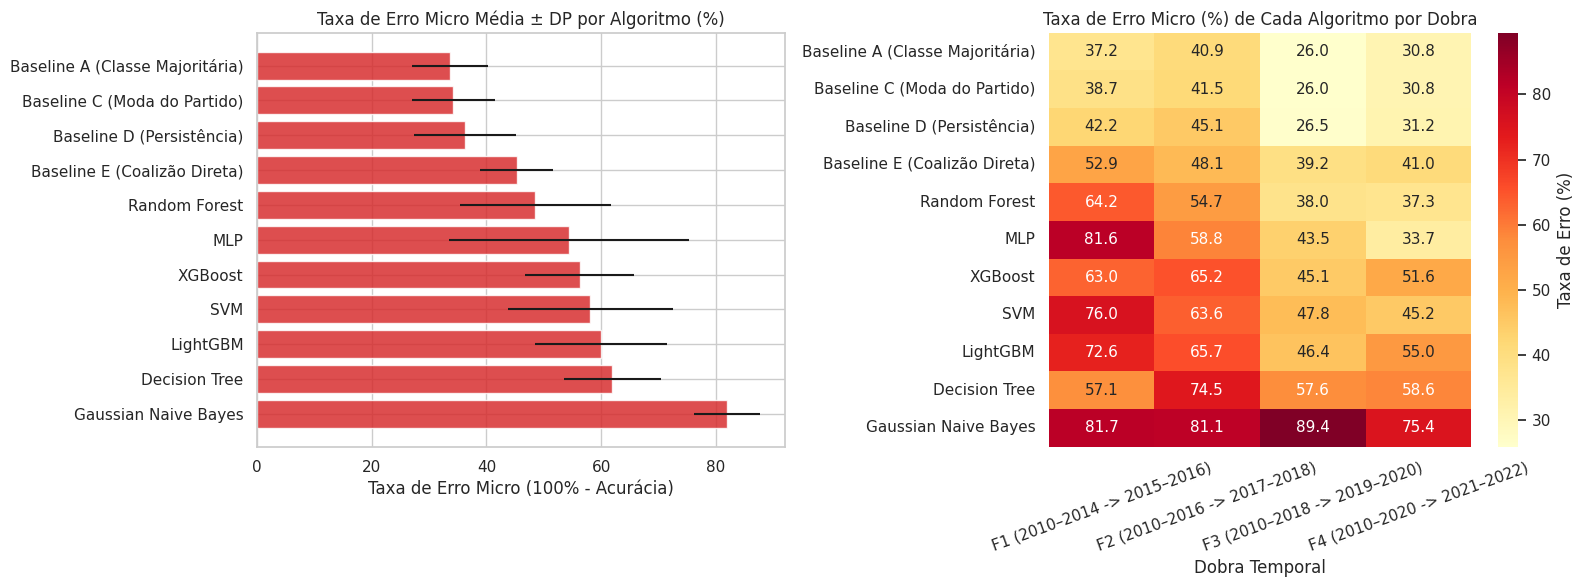

In [ ]:
# =============================================================================
# CÉLULA 7.1: TAXAS DE ERRO MICRO E MACRO (BILL) POR ALGORITMO E POR DOBRA
# =============================================================================
df_err = df_resultados.copy()
df_err["Taxa de Erro Micro (%)"] = df_err["Taxa de Erro Micro"] * 100.0
df_err["Taxa de Erro Macro Bill (%)"] = df_err["Taxa de Erro Macro (Bill)"] * 100.0

resumo_erros = (
    df_err.groupby("Modelo")[["Taxa de Erro Micro (%)", "Taxa de Erro Macro Bill (%)"]]
    .agg(["mean", "std"])
    .round(2)
    .sort_values(("Taxa de Erro Micro (%)", "mean"), ascending=True)
)
print("=" * 85)
print("RANKING DE TAXAS DE ERRO DE CADA ALGORITMO E BASELINE (MÉDIA ± DP NAS 4 DOBRAS, EM %)")
print("=" * 85)
print(resumo_erros.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Ranking médio de Taxa de Erro Micro (%) por algoritmo
ordem_mod = resumo_erros.index.tolist()
medias_err = resumo_erros[("Taxa de Erro Micro (%)", "mean")].values
stds_err   = resumo_erros[("Taxa de Erro Micro (%)", "std")].fillna(0.0).values
axes[0].barh(ordem_mod[::-1], medias_err[::-1], xerr=stds_err[::-1], color="#d62728", alpha=0.82)
axes[0].set_title("Taxa de Erro Micro Média ± DP por Algoritmo (%)")
axes[0].set_xlabel("Taxa de Erro Micro (100% - Acurácia)")

# 2. Heatmap Modelo × Dobra
piv_err = df_err.pivot(index="Modelo", columns="Dobra", values="Taxa de Erro Micro (%)").reindex(ordem_mod)
sns.heatmap(piv_err, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Taxa de Erro (%)"}, ax=axes[1])
axes[1].set_title("Taxa de Erro Micro (%) de Cada Algoritmo por Dobra")
axes[1].set_xlabel("Dobra Temporal")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 7.2 Decomposição da Taxa de Erro de Cada Algoritmo por Classe de Voto (`FAVORAVEL`, `CONTRARIO`, `ABSTENCAO`, `AUSENCIA`)
Avaliação da taxa de erro condicional por classe real ($	ext{Erro}_c = 1 - 	ext{Recall}_c = \Pr(\hat{y}
eq c \mid y = c)$) para **cada um dos 7 algoritmos supervisionados**, revelando a dificuldade específica de cada família de modelos em votos positivos, negativos, abstenções e ausências.

Taxa de Erro Específica por Classe Real (1 - Recall, em %) para Cada Algoritmo Supervisionado:
                      FAVORAVEL  CONTRARIO  ABSTENCAO  AUSENCIA  Erro Global (%)
XGBoost                   39.87      92.39      66.01     67.36            52.23
Random Forest             23.19      90.73      83.20     66.43            41.73
Decision Tree             55.75      73.37      79.38     67.03            61.19
MLP                       23.02      92.02      83.87     86.51            43.48
SVM                       38.64      82.81      72.65     69.63            50.59
LightGBM                  42.94      93.77      62.97     70.38            54.57
Gaussian Naive Bayes      92.50      55.48      66.88     53.24            81.63


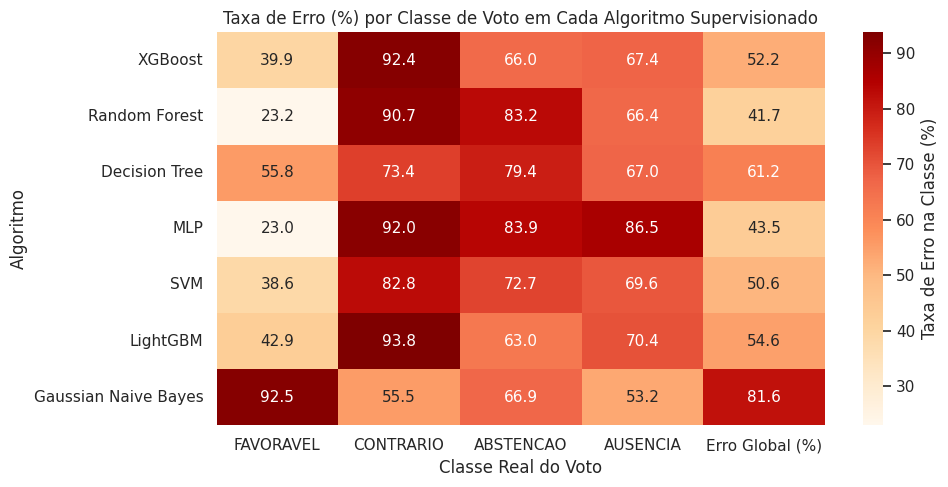

In [ ]:
# =============================================================================
# CÉLULA 7.2: TAXA DE ERRO DE CADA ALGORITMO POR CLASSE DE VOTO (1 - RECALL)
# =============================================================================
modelos_sup = list(get_base_classifiers().keys())
erros_por_classe = {}

y_real_all = np.concatenate([dados_teste_fold[f["id"]][1] for f in FOLDS])
classes_nomes = list(le_target.classes_)

for m_name in modelos_sup:
    y_pred_all = np.concatenate([predicoes_fold[(f["id"], m_name)] for f in FOLDS])
    taxas_cls = {}
    for cls_idx, cls_nome in enumerate(classes_nomes):
        mask_cls = (y_real_all == cls_idx)
        taxas_cls[cls_nome] = float((y_pred_all[mask_cls] != cls_idx).mean() * 100.0) if mask_cls.any() else np.nan
    taxas_cls["Erro Global (%)"] = float((y_pred_all != y_real_all).mean() * 100.0)
    erros_por_classe[m_name] = taxas_cls

df_erro_classe = pd.DataFrame(erros_por_classe).T[
    ["FAVORAVEL", "CONTRARIO", "ABSTENCAO", "AUSENCIA", "Erro Global (%)"]
].round(2)

print("Taxa de Erro Específica por Classe Real (1 - Recall, em %) para Cada Algoritmo Supervisionado:")
print(df_erro_classe.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    df_erro_classe, annot=True, fmt=".1f", cmap="OrRd",
    cbar_kws={"label": "Taxa de Erro na Classe (%)"}, ax=ax
)
ax.set_title("Taxa de Erro (%) por Classe de Voto em Cada Algoritmo Supervisionado")
ax.set_xlabel("Classe Real do Voto")
ax.set_ylabel("Algoritmo")
plt.tight_layout()
plt.show()

### 7.3 Taxa de Erro de Cada Algoritmo por Coalizão Governamental, por Partido e Senadores Dissidentes
Cruzamento da taxa de erro (%) de **todos os 7 algoritmos supervisionados** por bloco de coalizão (`BASE`, `OPOSICAO`, `INDEPENDENTE`, `DESCONHECIDO`) e pelas 12 maiores bancadas partidárias, seguido da identificação dos 10 senadores com maior taxa média de desvio no período de teste.

Taxa de Erro (%) de Cada Algoritmo por Situação na Coalizão:
                   XGBoost  Random Forest  Decision Tree    MLP    SVM  LightGBM  Gaussian Naive Bayes
situacao_coalizao                                                                                     
BASE                 55.38          42.71          62.31  45.10  51.96     58.33                 81.95
DESCONHECIDO         59.32          52.17          67.42  69.87  68.93     56.87                 78.15
INDEPENDENTE         44.10          37.81          57.48  39.13  46.04     47.23                 82.32
OPOSICAO             49.19          41.51          60.61  40.57  49.18     49.20                 80.20

Taxa de Erro (%) de Cada Algoritmo nos 12 Maiores Partidos:
               XGBoost  Random Forest  Decision Tree    MLP    SVM  LightGBM  Gaussian Naive Bayes
sigla_partido                                                                                     
MDB              55.62          44.40          62.43  46.37  5

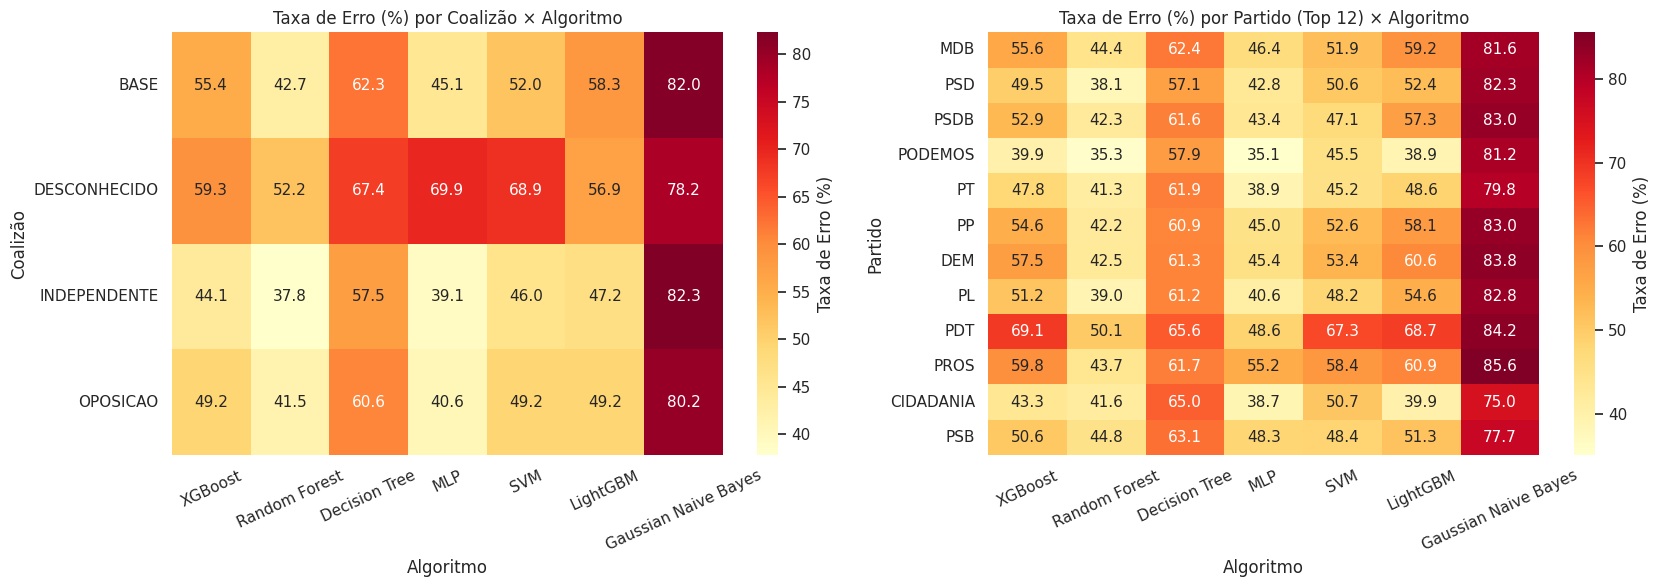


Top 10 Senadores com Maior Taxa Média de Erro (%) nos 7 Algoritmos:
  nome_parlamentar sigla_partido  votos  taxa_erro_media
        Osmar Dias           PDT     21            93.20
     Gerson Camata           MDB     21            92.52
   Eduardo Velloso         UNIÃO     28            87.76
     Hugo Napoleão           PSD     21            85.03
Leomar Quintanilha           MDB     21            85.03
      Luiz Pastore           MDB     20            84.29
João Alberto Souza           MDB    105            81.22
    Roberto Freire     CIDADANIA     21            80.95
     Carlos Wilson            PT     21            80.27
      Edison Lobão           MDB    112            78.95


In [ ]:
# =============================================================================
# CÉLULA 7.3: TAXA DE ERRO DE CADA ALGORITMO POR COALIZÃO, PARTIDO E SENADOR
# =============================================================================
df_te_concat = pd.concat([dados_teste_fold[f["id"]][0] for f in FOLDS], ignore_index=True)
y_real_concat = np.concatenate([dados_teste_fold[f["id"]][1] for f in FOLDS])

# Calcula coluna de erro binário (0/100%) para cada um dos 7 algoritmos
cols_erro_alg = []
for m_name in modelos_sup:
    y_p = np.concatenate([predicoes_fold[(f["id"], m_name)] for f in FOLDS])
    col_err = f"erro_{m_name}"
    df_te_concat[col_err] = (y_p != y_real_concat).astype(float) * 100.0
    cols_erro_alg.append(col_err)

# 1. Matriz de Taxa de Erro (%) por Coalizão × Algoritmo
err_coal_alg = df_te_concat.groupby("situacao_coalizao")[cols_erro_alg].mean().round(2)
err_coal_alg.columns = modelos_sup
print("Taxa de Erro (%) de Cada Algoritmo por Situação na Coalizão:")
print(err_coal_alg.to_string())

# 2. Matriz de Taxa de Erro (%) por Partido (Top 12) × Algoritmo
top12_p_te = df_te_concat["sigla_partido"].value_counts().head(12).index.tolist()
err_part_alg = (
    df_te_concat[df_te_concat["sigla_partido"].isin(top12_p_te)]
    .groupby("sigla_partido")[cols_erro_alg].mean()
    .reindex(top12_p_te).round(2)
)
err_part_alg.columns = modelos_sup
print("\nTaxa de Erro (%) de Cada Algoritmo nos 12 Maiores Partidos:")
print(err_part_alg.to_string())

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(
    err_coal_alg, annot=True, fmt=".1f", cmap="YlOrRd",
    cbar_kws={"label": "Taxa de Erro (%)"}, ax=axes[0]
)
axes[0].set_title("Taxa de Erro (%) por Coalizão × Algoritmo")
axes[0].set_xlabel("Algoritmo")
axes[0].set_ylabel("Coalizão")
axes[0].tick_params(axis="x", rotation=25)

sns.heatmap(
    err_part_alg, annot=True, fmt=".1f", cmap="YlOrRd",
    cbar_kws={"label": "Taxa de Erro (%)"}, ax=axes[1]
)
axes[1].set_title("Taxa de Erro (%) por Partido (Top 12) × Algoritmo")
axes[1].set_xlabel("Algoritmo")
axes[1].set_ylabel("Partido")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# 3. Top 10 Senadores com Maior Taxa Média de Erro entre os 7 Algoritmos (≥20 votos no teste)
df_te_concat["erro_medio_7_algs"] = df_te_concat[cols_erro_alg].mean(axis=1)
err_sen = (
    df_te_concat.groupby(["nome_parlamentar", "sigla_partido"])
    .agg(votos=("erro_medio_7_algs", "count"), taxa_erro_media=("erro_medio_7_algs", "mean"))
    .reset_index()
)
top_sen_err = err_sen[err_sen["votos"] >= 20].sort_values("taxa_erro_media", ascending=False).head(10).round(2)
print("\nTop 10 Senadores com Maior Taxa Média de Erro (%) nos 7 Algoritmos:")
print(top_sen_err.to_string(index=False))